<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/OT-day2/OT_Day2_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ONNX·TensorRT Day 2 — ONNX 속 들여다보기: 코드로 읽고, 오류를 고치기

**온디바이스 AI · ONNX·TensorRT 2/5 · 11/5(목)** · Google Colab (하드웨어 없음) · PyTorch · ONNX · ONNX Runtime · onnxslim

어제는 4단계(**내보내기 → 열어보기 → 실행하기 → 확인하기**)를 다섯 모델에 반복했습니다. 오늘은 그중 **'열어보기'를 코드로 깊게** 하고, 어제 막혔던 것들을 하나씩 풉니다.

- 어제 Netron **그림**으로 본 그래프를 오늘은 **코드**로 읽습니다.
- 어제 `Got: 4 Expected: 1` 로 막힌 **배치 크기**를 자유롭게 만듭니다.
- 어제는 export 가 늘 성공했습니다. 오늘은 **export 가 성공했는데 틀리는 경우**와 **export 가 실패하는 경우**를 일부러 만나고 고칩니다.

오늘의 목표

1. ONNX 파일의 구조 (ModelProto → GraphProto → input · node · initializer · output) 를 코드로 꺼내 읽을 수 있다.
2. 노드의 input · output **이름으로 화살표를 따라가고**, 가중치 · 속성을 꺼내 **그래프 요약 표 `describe_onnx()`** 를 만든다.
3. **opset** 이 무엇인지 말하고, **checker** 로 고장 난 파일을 찾고, **shape_inference** 로 중간 shape 를 채운다.
4. **dynamic_axes** 로 배치 크기가 자유로운 ONNX 를 만들고 100장을 한 번에 실행한다.
5. **조용히 틀리는 export 3가지** (파이썬 if · NumPy 값 · 숫자로 고정한 배치) 를 찾아 고친다.
6. **미지원 연산** 오류를 읽고 지원되는 연산으로 바꾸며, **onnxslim** 으로 그래프를 단순화한다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 1 복습 퀴즈 · 4단계 다시 · 오늘의 지도 |
| 2 | 10:00–10:50 | ONNX 파일 = 그래프 — input · node · initializer · output |
| 3 | 11:00–11:50 | 가중치 · 속성 꺼내기 — 그래프 요약 표 `describe_onnx()` |
| 4 | 13:00–13:50 | opset · checker · shape_inference |
| 5 | 14:00–14:50 | 배치 크기 자유롭게 — `dynamic_axes` |
| 6 | 15:00–15:50 | 조용히 틀리는 export 3가지 — if · NumPy · 고정 배치 |
| 7 | 16:00–16:50 | 미지원 연산 고치기 · onnxslim 단순화 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 고장 난 BrightNet 고쳐 배포하기 · 채점 |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → T4 GPU* 를 고르고, *파일 → Drive에 사본 저장* 후 사본에서 작업합니다. (오늘도 CPU 로 모두 실행됩니다.)
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다.
3. 막히면 **🔒 정답 보기** 셀을 실행하세요. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
4. 매 교시는 **보기 → 따라하기 → 바꿔보기** 순서입니다. `🔁 바꿔보기` 셀은 숫자 하나만 바꿔 결과를 관찰합니다.
5. 8교시 미니 프로젝트는 이 노트북 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/OT_Day2.pdf](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/OT_Day2.pdf) |
| 🔭 Netron (브라우저용) | [https://netron.app](https://netron.app) |

**오늘의 데이터 · 모델** — 어제와 같은 **SimpleConvNet** (MNIST, `mnist_cnn.pt`) · **SafetyNet** (64×64, 3 클래스) · MNIST 100장 · 사진 3장, 그리고 오늘 처음 보는 작은 모델들 (GELU 모델 · Gate · 센서 중앙값 · ViewNet · **BrightNet**).

In [ ]:
# ▶ 설치 셀 — ONNX · ONNX Runtime · onnxslim · Netron. 처음 한 번, 약 30초
%pip install -q onnx onnxruntime onnxscript onnxslim netron

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요 (Day 1 의 도구 · 모델 정의를 그대로 가져옵니다)
import os, time, inspect, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import onnx
import onnxruntime as ort
import onnxslim

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_colwidth", 60)
torch.manual_seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/OT-day2"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 강사에게 받은 파일을 왼쪽 📁 파일 창의 data 폴더에 올린 뒤 다시 실행하세요.")
    return path

def show_netron(path, port=8081, height=520):
    try:
        import netron
        from google.colab import output
        netron.start(path, address=("localhost", port), browse=False)
        output.serve_kernel_port_as_iframe(port, height=str(height))
    except ImportError:
        print(f"Colab 이 아닙니다 → {path} 를 내려받아 https://netron.app 에 끌어다 놓으세요.")

def onnx_report(path):                       # Day 1 8교시 과제 4
    model = onnx.load(path)
    s = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    return {"size_kb": round(os.path.getsize(path) / 1024, 1), "n_nodes": len(model.graph.node),
            "ops": sorted(set(n.op_type for n in model.graph.node)),
            "inputs": [(i.name, i.shape) for i in s.get_inputs()], "outputs": [(o.name, o.shape) for o in s.get_outputs()]}

class SimpleConvNet(nn.Module):              # VB Day 1 · OT Day 1 6교시
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 30, 5)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(30 * 12 * 12, 100)
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

class SafetyNet(nn.Module):                  # OT Day 1 8교시
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 3))

    def forward(self, x):
        return self.head(self.features(x))

def make_safety():
    torch.manual_seed(7)
    m = SafetyNet()
    with torch.no_grad():
        for b in m.modules():
            if isinstance(b, nn.BatchNorm2d):
                b.running_mean.uniform_(-0.2, 0.2); b.running_var.uniform_(0.5, 1.5)
    return m.eval()

print("PyTorch", torch.__version__, "| ONNX", onnx.__version__, "| ONNX Runtime", ort.__version__, "| onnxslim", onnxslim.__version__)

In [ ]:
# ▶ 데이터 셀 — MNIST 100장 · 학습된 SimpleConvNet
d = np.load(fetch("mnist_sample.npz"))
digits, labels = d["images"], d["labels"]                 # (100, 28, 28) uint8, (100,)
cnn = SimpleConvNet()
cnn.load_state_dict(torch.load(fetch("mnist_cnn.pt"), map_location="cpu"))
print("digits", digits.shape, digits.dtype, "| labels", labels[:10])

## 1교시 — Day 1 복습 · 4단계 다시 · 오늘의 지도

| 시간 | 할 일 |
|---|---|
| 09:00–09:15 | **Day 1 복습 퀴즈 20문항** (Google Forms — 강사가 링크 공유) |
| 09:15–09:35 | 문제 1-1 · 1-2 — 어제의 4단계를 혼자서 |
| 09:35–09:50 | 오늘의 지도 — 어제 막혔던 것 4가지 |

> 🎬 **애니메이션** [D2-1 4단계 다시 · 오늘의 지도](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

**문제 1-1** 어제의 4단계를 한 셀에 다시 씁니다. `cnn` 을 **실행 모드**로 바꾸고, MNIST **1장** 모양의 더미 입력으로 `mnist_cnn.onnx` 를 만든 뒤, 첫 번째 숫자 사진으로 ONNX Runtime 과 PyTorch 결과를 비교하세요.

In [ ]:
cnn.____()                                                                   # 0. 실행 모드
torch.onnx.export(cnn, torch.zeros(____), "mnist_cnn.onnx",                  # 1. 내보내기
                  input_names=["input"], output_names=["logits"], **EXPORT_KW)
sess_cnn = ort.InferenceSession("mnist_cnn.onnx", providers=["CPUExecutionProvider"])   # 3. 실행하기
x0 = (digits[0].astype(np.float32) / 255)[None, None]                       # (1, 1, 28, 28)
y_ort = sess_cnn.run(None, {"____": x0})[0]
with torch.no_grad():
    y_pt = cnn(torch.from_numpy(x0)).numpy()
same = np.____(y_ort, y_pt, atol=1e-5)                                       # 4. 확인하기
print("예측", y_ort.argmax(), "| 정답", labels[0], "| PyTorch 와 같다:", same)

In [ ]:
assert not cnn.training and same and onnx_report("mnist_cnn.onnx")["inputs"] == [("input", [1, 1, 28, 28])]
print("✅ 4단계 완료 —", onnx_report("mnist_cnn.onnx")["ops"])

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACmNubi5ldmFsKCkgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIyAwLiDsi6Ttlokg66qo65OcCnRvcmNoLm9ubngu"
    "ZXhwb3J0KGNubiwgdG9yY2guemVyb3MoMSwgMSwgMjgsIDI4KSwgIm1uaXN0X2Nubi5vbm54IiwgICAgICAgICAg"
    "IyAxLiDrgrTrs7TrgrTquLAKICAgICAgICAgICAgICAgICAgaW5wdXRfbmFtZXM9WyJpbnB1dCJdLCBvdXRwdXRf"
    "bmFtZXM9WyJsb2dpdHMiXSwgKipFWFBPUlRfS1cpCnNlc3NfY25uID0gb3J0LkluZmVyZW5jZVNlc3Npb24oIm1u"
    "aXN0X2Nubi5vbm54IiwgcHJvdmlkZXJzPVsiQ1BVRXhlY3V0aW9uUHJvdmlkZXIiXSkgICAjIDMuIOyLpO2Wie2V"
    "mOq4sAp4MCA9IChkaWdpdHNbMF0uYXN0eXBlKG5wLmZsb2F0MzIpIC8gMjU1KVtOb25lLCBOb25lXSAgICAgICAg"
    "ICAgICAgICAgICAgICAgIyAoMSwgMSwgMjgsIDI4KQp5X29ydCA9IHNlc3NfY25uLnJ1bihOb25lLCB7ImlucHV0"
    "IjogeDB9KVswXQp3aXRoIHRvcmNoLm5vX2dyYWQoKToKICAgIHlfcHQgPSBjbm4odG9yY2guZnJvbV9udW1weSh4"
    "MCkpLm51bXB5KCkKc2FtZSA9IG5wLmFsbGNsb3NlKHlfb3J0LCB5X3B0LCBhdG9sPTFlLTUpICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAjIDQuIO2ZleyduO2VmOq4sApwcmludCgi7JiI7LihIiwgeV9vcnQuYXJn"
    "bWF4KCksICJ8IOygleuLtSIsIGxhYmVsc1swXSwgInwgUHlUb3JjaCDsmYAg6rCZ64ukOiIsIHNhbWUpCgrwn5Kh"
    "IO2VtOyEpAoy64uo6rOEICfsl7TslrTrs7TquLAnIOqwgCDruaDsoLgg7J6I7KOgPyDqt7jqsowg7Jik64qYIO2V"
    "mOujqOydmCDso7zsoJzsnoXri4jri6Qg4oCUIE5ldHJvbiDrjIDsi6Ag7L2U65Oc66GcIOyXveuLiOuLpC4="
).decode("utf-8"))

**문제 1-2** **기억으로 예측하기** — `mnist_cnn.onnx` 의 노드(상자) 수와 가중치 텐서(initializer) 수는? 실행하지 말고 어제 6교시를 떠올려 숫자로 쓰세요. (힌트: Conv · Gemm · Gemm 은 각각 weight · bias 를 가진다)

In [ ]:
n_nodes_guess = ____
n_init_guess = ____

In [ ]:
_m = onnx.load("mnist_cnn.onnx")
assert (n_nodes_guess, n_init_guess) == (len(_m.graph.node), len(_m.graph.initializer)), (len(_m.graph.node), len(_m.graph.initializer))
print("✅ 노드", n_nodes_guess, "개 · 가중치 텐서", n_init_guess, "개")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACm5fbm9kZXNfZ3Vlc3MgPSA3Cm5faW5pdF9ndWVzcyA9IDYKCvCfkqEg"
    "7ZW07ISkCuuFuOuTnDogQ29udiDCtyBSZWx1IMK3IE1heFBvb2wgwrcgRmxhdHRlbiDCtyBHZW1tIMK3IFJlbHUg"
    "wrcgR2VtbSA9IDfqsJwuCuqwgOykkey5mCDthZDshJw6IGNvbnYud2VpZ2h0IMK3IGNvbnYuYmlhcyDCtyBmYzEu"
    "d2VpZ2h0IMK3IGZjMS5iaWFzIMK3IGZjMi53ZWlnaHQgwrcgZmMyLmJpYXMgPSA26rCcLgrsnbQg65GQIOyIq+ye"
    "kOulvCDsmKTripggMuq1kOyLnOyXkCDsvZTrk5wg7ZWcIOykhOyUqeycvOuhnCDqurzrg4Xri4jri6Qg4oCUIGxl"
    "bihncmFwaC5ub2RlKSwgbGVuKGdyYXBoLmluaXRpYWxpemVyKS4="
).decode("utf-8"))

### 오늘의 지도 — 어제 막혔던 것 4가지

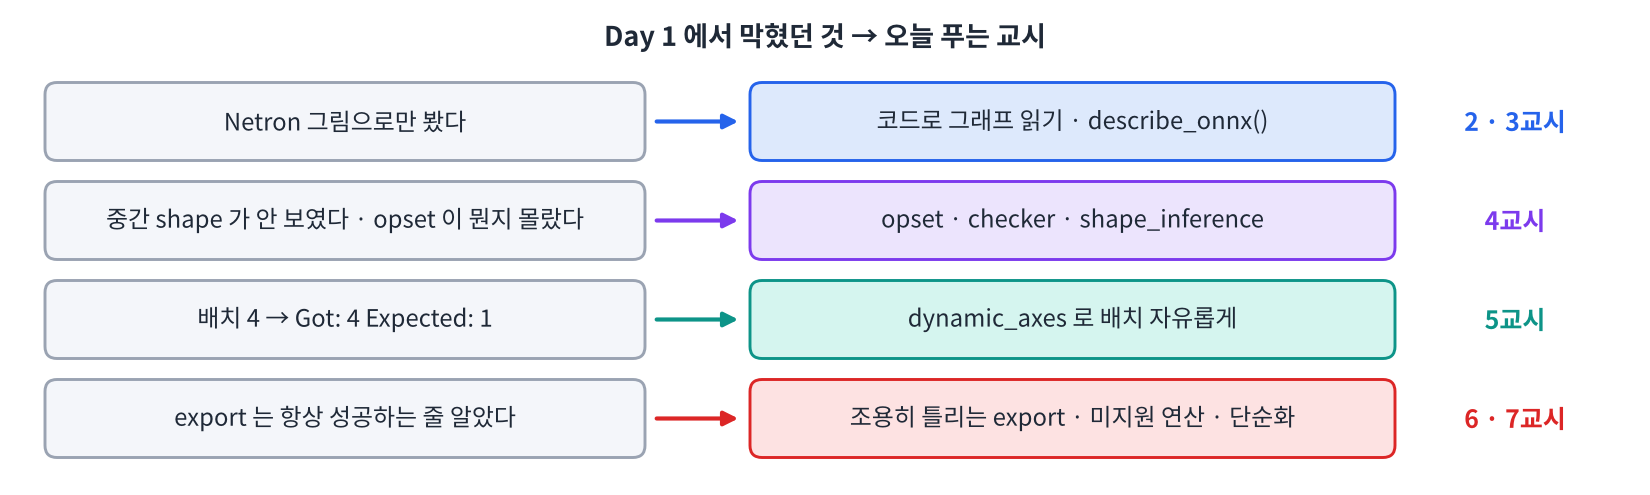

In [ ]:
#@title 🖼 그림 — Day 1 에서 막혔던 것 → 오늘 푸는 교시
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f1_map.png", embed=True, width=860))

#### 📌 1교시 정리

- 4단계: **eval → export(이름 · shape) → 열어보기 → run · allclose**. 오늘은 '열어보기' 를 코드로.
- `mnist_cnn.onnx` = 노드 7개 · 가중치 텐서 6개 — 숫자로 기억해 두면 오늘 확인 셀이 쉬워집니다.

## 2교시 — ONNX 파일 = 그래프: input · node · initializer · output

`onnx.load` 로 읽은 객체는 **상자 안의 상자** 구조입니다. 가장 바깥이 모델(ModelProto), 그 안에 그래프(GraphProto), 그래프 안에 네 가지 목록이 있습니다.

> 🎬 **애니메이션** [D2-2 ONNX 파일의 속 구조](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

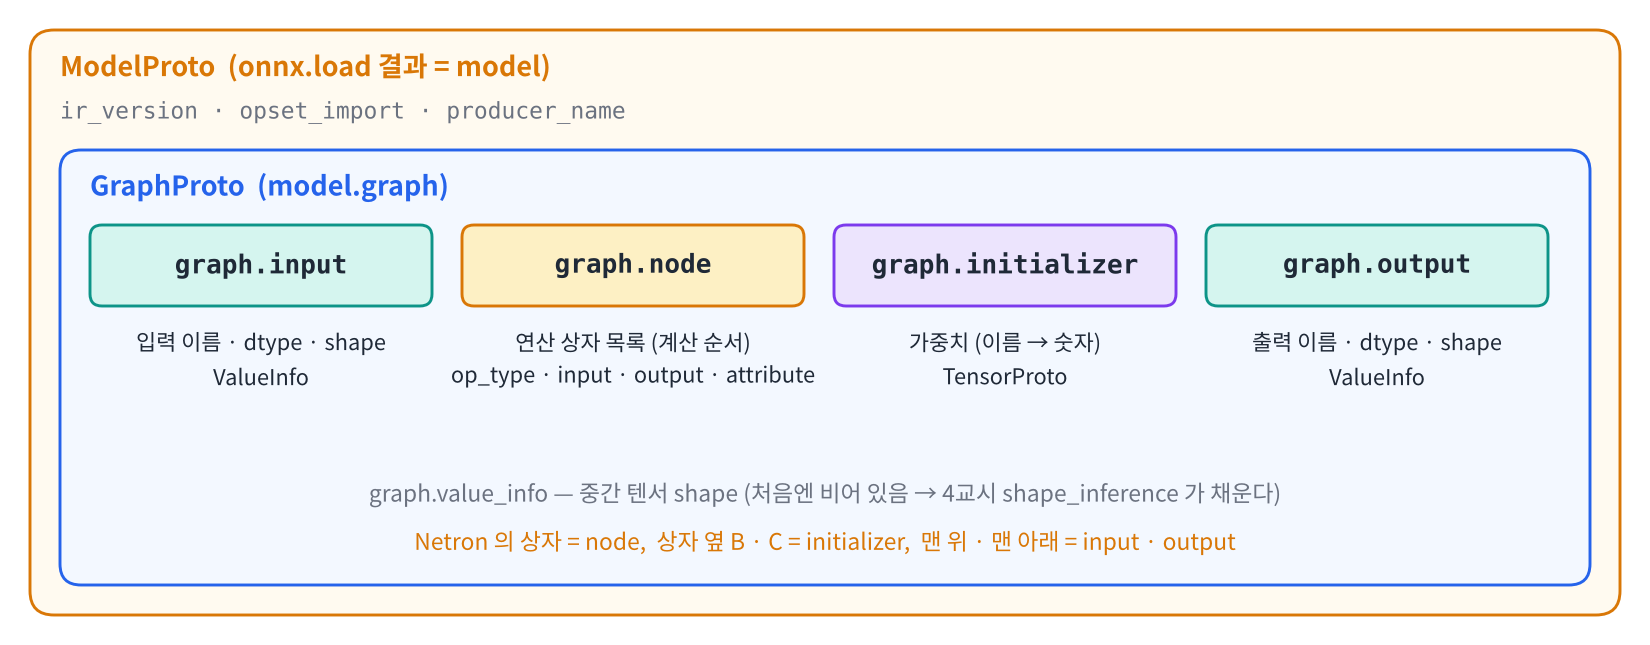

In [ ]:
#@title 🖼 그림 — ModelProto → GraphProto → input · node · initializer · output
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f2_proto.png", embed=True, width=860))

### 보기 — 가장 바깥 상자: 모델 정보

In [ ]:
m = onnx.load("mnist_cnn.onnx")
g = m.graph
print(type(m).__name__, "→", type(g).__name__)
print("ir_version :", m.ir_version, "   (ONNX 파일 형식 버전)")
print("opset      :", m.opset_import[0].version, "   (연산 사전의 판 번호 — 4교시)")
print("producer   :", m.producer_name, m.producer_version)

**문제 2-1** 그래프 안의 네 가지 목록의 **길이**를 구하세요. 이름은 그림의 네 상자 그대로입니다: `input` · `output` · `node` · `initializer`.

In [ ]:
n_in = len(g.____)
n_out = len(g.____)
n_node = len(g.____)
n_init = len(g.____)
print(f"input {n_in} · output {n_out} · node {n_node} · initializer {n_init}")

In [ ]:
assert (n_in, n_out, n_node, n_init) == (1, 1, 7, 6); print("✅ 1교시 예측과 같다")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACm5faW4gPSBsZW4oZy5pbnB1dCkKbl9vdXQgPSBsZW4oZy5vdXRwdXQp"
    "Cm5fbm9kZSA9IGxlbihnLm5vZGUpCm5faW5pdCA9IGxlbihnLmluaXRpYWxpemVyKQpwcmludChmImlucHV0IHtu"
    "X2lufSDCtyBvdXRwdXQge25fb3V0fSDCtyBub2RlIHtuX25vZGV9IMK3IGluaXRpYWxpemVyIHtuX2luaXR9IikK"
    "CvCfkqEg7ZW07ISkCmlucHV0IDEgKOyCrOynhCksIG91dHB1dCAxIChsb2dpdHMpLCBub2RlIDcsIGluaXRpYWxp"
    "emVyIDYuIOqwgOykkey5mOuKlCBpbnB1dCDsl5Ag65Ok7Ja0IOyeiOyngCDslYrsirXri4jri6Qg4oCUCifrsJTq"
    "uaXsl5DshJwg64Sj7Ja0IOyjvOuKlCDqsoMnIOydgCDsgqzsp4Trv5DsnbTqs6AsIOqwgOykkey5mOuKlCDtjIzs"
    "nbwg7JWI7JeQIOydtOuvuCDrk6TslrQg7J6I6riwIOuVjOusuOyeheuLiOuLpC4="
).decode("utf-8"))

**문제 2-2** **입력 · 출력의 shape 읽기** — `ValueInfo` 의 shape 는 `type.tensor_type.shape.dim` 목록입니다. 각 축은 숫자(`dim_value`) 이거나 이름(`dim_param`, 5교시의 `'batch'` 같은 것) 입니다. 숫자가 0 이면 이름을 쓰도록 `shape_of` 를 완성하세요.

In [ ]:
def shape_of(vi):
    return [d.dim_value if d.dim_value else d.____ for d in vi.type.tensor_type.shape.dim]

for vi in list(g.input) + list(g.output):
    print(vi.name, shape_of(vi))

In [ ]:
assert shape_of(g.input[0]) == [1, 1, 28, 28] and shape_of(g.output[0]) == [1, 10]; print("✅ input [1, 1, 28, 28] → logits [1, 10]")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRlZiBzaGFwZV9vZih2aSk6CiAgICByZXR1cm4gW2QuZGltX3ZhbHVl"
    "IGlmIGQuZGltX3ZhbHVlIGVsc2UgZC5kaW1fcGFyYW0gZm9yIGQgaW4gdmkudHlwZS50ZW5zb3JfdHlwZS5zaGFw"
    "ZS5kaW1dCgpmb3IgdmkgaW4gbGlzdChnLmlucHV0KSArIGxpc3QoZy5vdXRwdXQpOgogICAgcHJpbnQodmkubmFt"
    "ZSwgc2hhcGVfb2YodmkpKQoK8J+SoSDtlbTshKQK7KeA6riI7J2AIOuqqOuToCDstpXsnbQg7Iir7J6Q7J6F64uI"
    "64ukICjqs6DsoJUgc2hhcGUpLiA16rWQ7Iuc7JeQIGR5bmFtaWNfYXhlcyDroZwg64K067O064K066m0IOyyqyDs"
    "tpXsnbQgJ2JhdGNoJyDrnbzripQg7J2066aE7Jy866GcIOuwlOuAjOqzoCwK6re465WMIOydtCDtlajsiJjsnZgg"
    "ZGltX3BhcmFtIOyqveydtCDsk7DsnoXri4jri6QuIE9SVCDsnZggc2Vzcy5nZXRfaW5wdXRzKClbMF0uc2hhcGUg"
    "64+EIOqwmeydgCDsoJXrs7Trpbwg67O07JesIOykjeuLiOuLpC4="
).decode("utf-8"))

### 화살표는 어디에? — 이름이 같으면 이어진다

Netron 에서 본 화살표는 파일에 따로 저장되어 있지 않습니다. 각 노드는 **input 이름 목록**과 **output 이름 목록**만 가지고, **앞 노드의 output 이름 = 뒤 노드의 input 이름** 이면 화살표로 이어집니다.

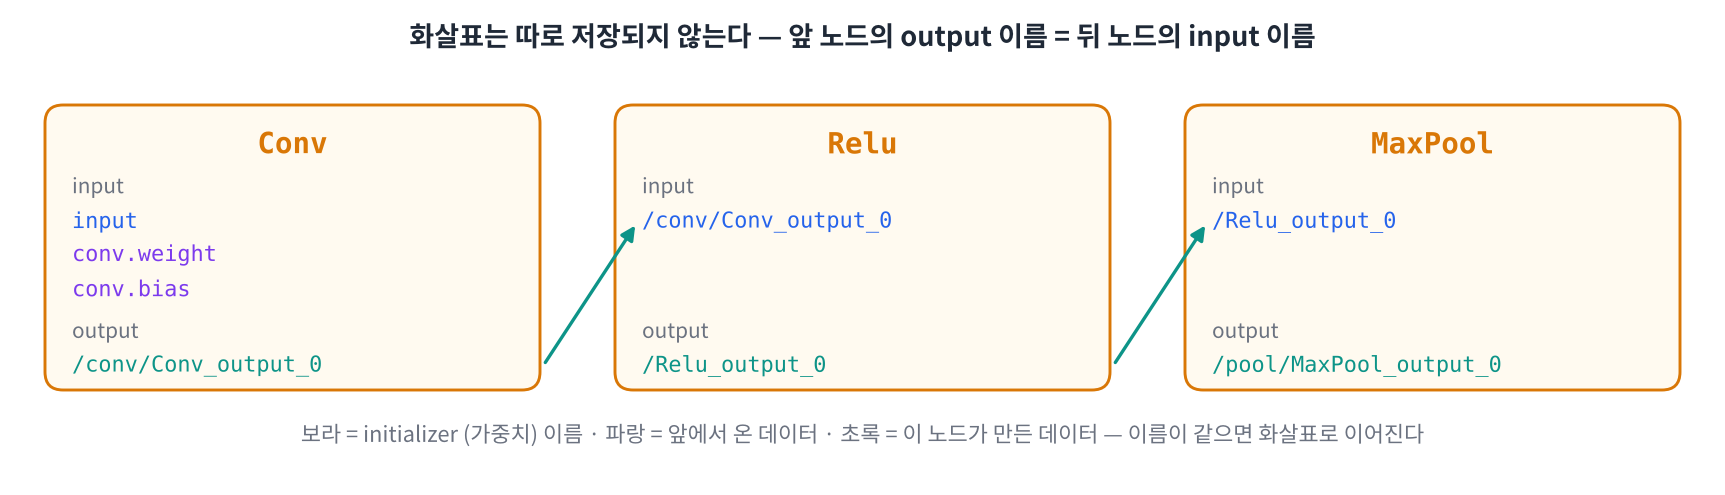

In [ ]:
#@title 🖼 그림 — 앞 노드의 output 이름 = 뒤 노드의 input 이름 → 화살표
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f2_names.png", embed=True, width=880))

In [ ]:
for i, n in enumerate(g.node):
    print(i, n.op_type.ljust(8), "input:", list(n.input), "→ output:", list(n.output))

**문제 2-3** 노드의 input 에는 **데이터**(앞에서 온 화살표) 와 **가중치**(initializer 이름) 가 섞여 있습니다. initializer 이름 집합 `init_names` 를 만들고, 각 노드의 input 을 둘로 나누세요.

In [ ]:
init_names = {t.____ for t in g.initializer}
rows = []
for n in g.node:
    data = [x for x in n.input if x not in init_names]
    weights = [x for x in n.input if x ____ init_names]
    rows.append((n.op_type, data, weights))
    print(n.op_type.ljust(8), "데이터:", data, "| 가중치:", weights)

In [ ]:
assert init_names == {"conv.weight", "conv.bias", "fc1.weight", "fc1.bias", "fc2.weight", "fc2.bias"}
assert sum(len(w) for _, _, w in rows) == 6 and all(len(dd) == 1 for _, dd, _ in rows); print("✅ 모든 노드는 데이터 화살표 1개 + 가중치 0 또는 2개")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACmluaXRfbmFtZXMgPSB7dC5uYW1lIGZvciB0IGluIGcuaW5pdGlhbGl6"
    "ZXJ9CnJvd3MgPSBbXQpmb3IgbiBpbiBnLm5vZGU6CiAgICBkYXRhID0gW3ggZm9yIHggaW4gbi5pbnB1dCBpZiB4"
    "IG5vdCBpbiBpbml0X25hbWVzXQogICAgd2VpZ2h0cyA9IFt4IGZvciB4IGluIG4uaW5wdXQgaWYgeCBpbiBpbml0"
    "X25hbWVzXQogICAgcm93cy5hcHBlbmQoKG4ub3BfdHlwZSwgZGF0YSwgd2VpZ2h0cykpCiAgICBwcmludChuLm9w"
    "X3R5cGUubGp1c3QoOCksICLrjbDsnbTthLA6IiwgZGF0YSwgInwg6rCA7KSR7LmYOiIsIHdlaWdodHMpCgrwn5Kh"
    "IO2VtOyEpArqsIDspJHsuZgg7J2066aE7J20IGNvbnYud2VpZ2h0IMK3IGZjMS5iaWFzIOyymOufvCBQeVRvcmNo"
    "IOuzgOyImCDsnbTrpoQg6re464yA66Gc7J6F64uI64ukLiBOZXRyb24g7J2YIEIgwrcgQyDqsIAg67CU66GcIOyd"
    "tOqygy4="
).decode("utf-8"))

**문제 2-4** **화살표 따라가기** — 입력 이름에서 출발해, 그 이름을 input 으로 갖는 노드를 찾고, 그 노드의 output 이름으로 넘어가기를 반복합니다. 출력 이름(`logits`) 에 닿으면 멈춥니다. 지나간 노드 종류를 순서대로 모으세요.

In [ ]:
name = g.input[0].name
path = []
while name != g.output[0].name:
    node = next(n for n in g.node if name in n.input)       # 이 이름을 받아 가는 노드
    path.append(node.op_type)
    name = node.____[0]                                      # 다음 화살표 이름
print(" → ".join(path))

In [ ]:
assert path == [n.op_type for n in g.node]; print("✅ 화살표를 따라가도 노드 순서와 같다 —", len(path), "개")

In [ ]:
#@title 🔒 정답 보기 2-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTQg4pSA4pSACm5hbWUgPSBnLmlucHV0WzBdLm5hbWUKcGF0aCA9IFtdCndoaWxlIG5h"
    "bWUgIT0gZy5vdXRwdXRbMF0ubmFtZToKICAgIG5vZGUgPSBuZXh0KG4gZm9yIG4gaW4gZy5ub2RlIGlmIG5hbWUg"
    "aW4gbi5pbnB1dCkgICAgICAgIyDsnbQg7J2066aE7J2EIOuwm+yVhCDqsIDripQg64W465OcCiAgICBwYXRoLmFw"
    "cGVuZChub2RlLm9wX3R5cGUpCiAgICBuYW1lID0gbm9kZS5vdXRwdXRbMF0gICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAjIOuLpOydjCDtmZTsgrTtkZwg7J2066aECnByaW50KCIg4oaSICIuam9pbihwYXRoKSkK"
    "CvCfkqEg7ZW07ISkCk9OTlgg64qUIOuFuOuTnOulvCAn6rOE7IKwIOyInOyEnOuMgOuhnCcg7KCA7J6l7ZW07JW8"
    "IO2VqeuLiOuLpCAodG9wb2xvZ2ljYWwgb3JkZXIpLiDqt7jrnpjshJwg7ZmU7IK07ZGc66W8IOuUsOudvOqwhCDs"
    "iJzshJwgPSBncmFwaC5ub2RlIOyInOyEnC4KNOq1kOyLnOyXkCDsnbQg6rec7LmZ7J2EIOydvOu2gOufrCDquajs"
    "hJwgY2hlY2tlciDqsIAg7J6h64qUIOqyg+ydhCDrtIXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `g.inputs` · `g.nodes` (복수형 s) → `AttributeError`. 이름은 단수형 `input` · `node` · `initializer` · `output` 입니다.
- `shape_of` 에서 `dim_value` 만 보면 이름 붙은 축이 **0** 으로 보입니다 (5교시).
- `onnx.load` 결과를 출력(`print(m)`) 하면 가중치 숫자까지 전부 찍혀 화면이 멈출 수 있습니다 — 필요한 부분만 꺼내세요.

#### 📌 2교시 정리

- `model = onnx.load(path)` → `model.graph` 안에 **input · node · initializer · output** 네 목록.
- 노드 = `op_type` + input 이름들 + output 이름들. **이름이 같으면 화살표.**
- 가중치는 input 이 아니라 initializer — 바깥에서 넣는 것은 사진뿐.

## 3교시 — 가중치 · 속성 꺼내기: 그래프 요약 표 `describe_onnx()`

2교시에 이름까지 읽었습니다. 이번엔 이름 뒤의 **숫자**(가중치) 와 노드의 **설정값**(속성 · attribute) 을 꺼내고, 모든 것을 **표 한 장**으로 요약하는 함수를 만듭니다. 오늘부터 모든 모델은 이 표로 먼저 봅니다.

> 🎬 **애니메이션** [D2-3 가중치 · 속성 꺼내기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

**문제 3-1** initializer 를 `{이름: NumPy 배열}` 딕셔너리 `W` 로 만드세요 (`onnx.numpy_helper.to_array`). 그리고 전체 원소 수 `total` 을 구하고, `conv.weight` 가 PyTorch 의 `cnn.conv.weight` 와 같은지 확인합니다.

In [ ]:
W = {t.name: onnx.numpy_helper.____(t) for t in g.initializer}
total = sum(a.____ for a in W.values())
for k, a in W.items():
    print(k.ljust(12), a.shape, a.dtype)
print("합계", f"{total:,}", "| conv.weight 같은가:", np.allclose(W["conv.weight"], cnn.conv.weight.detach().numpy()))

In [ ]:
assert total == 433_890 and W["fc1.weight"].shape == (100, 4320); print("✅ 433,890 개 = Day 1 의 파라미터 수")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSAClcgPSB7dC5uYW1lOiBvbm54Lm51bXB5X2hlbHBlci50b19hcnJheSh0"
    "KSBmb3IgdCBpbiBnLmluaXRpYWxpemVyfQp0b3RhbCA9IHN1bShhLnNpemUgZm9yIGEgaW4gVy52YWx1ZXMoKSkK"
    "Zm9yIGssIGEgaW4gVy5pdGVtcygpOgogICAgcHJpbnQoay5sanVzdCgxMiksIGEuc2hhcGUsIGEuZHR5cGUpCnBy"
    "aW50KCLtlanqs4QiLCBmInt0b3RhbDosfSIsICJ8IGNvbnYud2VpZ2h0IOqwmeydgOqwgDoiLCBucC5hbGxjbG9z"
    "ZShXWyJjb252LndlaWdodCJdLCBjbm4uY29udi53ZWlnaHQuZGV0YWNoKCkubnVtcHkoKSkpCgrwn5KhIO2VtOyE"
    "pAouc2l6ZSA9IOybkOyGjCDqsJzsiJggKHNoYXBlIOulvCDrqqjrkZAg6rOx7ZWcIOqwkikuIGZjMS53ZWlnaHQg"
    "7ZWY64KY6rCAIDQzMiwwMDAg6rCcIOKAlCDsoITssrTsnZggOTkuNiUg6rCAIOuniOyngOuniSBGbGF0dGVuIOuS"
    "pCBHZW1tIOyXkCDsnojsirXri4jri6Qu"
).decode("utf-8"))

**문제 3-2** **노드의 속성(attribute)** — Conv 의 커널 크기 · stride · padding 같은 설정은 `node.attribute` 에 있습니다. `onnx.helper.get_attribute_value` 로 값을 꺼내 노드마다 `{속성 이름: 값}` 딕셔너리를 만드세요.

In [ ]:
def attrs_of(node):
    return {a.name: onnx.helper.____(a) for a in node.attribute}

for n in g.node:
    print(n.op_type.ljust(8), attrs_of(n))

In [ ]:
conv_a, pool_a = attrs_of(g.node[0]), attrs_of(g.node[2])
assert conv_a["kernel_shape"] == [5, 5] and pool_a["kernel_shape"] == [2, 2] and pool_a["strides"] == [2, 2]
print("✅ Conv 5×5 · MaxPool 2×2 stride 2 — PyTorch 코드 nn.Conv2d(1, 30, 5) · nn.MaxPool2d(2) 와 같다")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmRlZiBhdHRyc19vZihub2RlKToKICAgIHJldHVybiB7YS5uYW1lOiBv"
    "bm54LmhlbHBlci5nZXRfYXR0cmlidXRlX3ZhbHVlKGEpIGZvciBhIGluIG5vZGUuYXR0cmlidXRlfQoKZm9yIG4g"
    "aW4gZy5ub2RlOgogICAgcHJpbnQobi5vcF90eXBlLmxqdXN0KDgpLCBhdHRyc19vZihuKSkKCvCfkqEg7ZW07ISk"
    "CkNvbnY6IGtlcm5lbF9zaGFwZSBbNSwgNV0gwrcgc3RyaWRlcyBbMSwgMV0gwrcgcGFkcyBbMCwgMCwgMCwgMF0g"
    "KOychCDCtyDsmbwgwrcg7JWE656YIMK3IOyYpOuluCkgwrcgZGlsYXRpb25zIMK3IGdyb3VwLgpHZW1tIOydmCB0"
    "cmFuc0IgPSAxIOydgCBEYXkgMSAz6rWQ7Iuc7JeQIE5ldHJvbiDsl5DshJwg67O4IOq3uCDqsJLsnoXri4jri6Qu"
    "IFJlbHUgwrcgRmxhdHRlbiDsspjrn7wg7IaN7ISx7J20IOyXhuycvOuptCDruYgg65SV7IWU64SI66asLg=="
).decode("utf-8"))

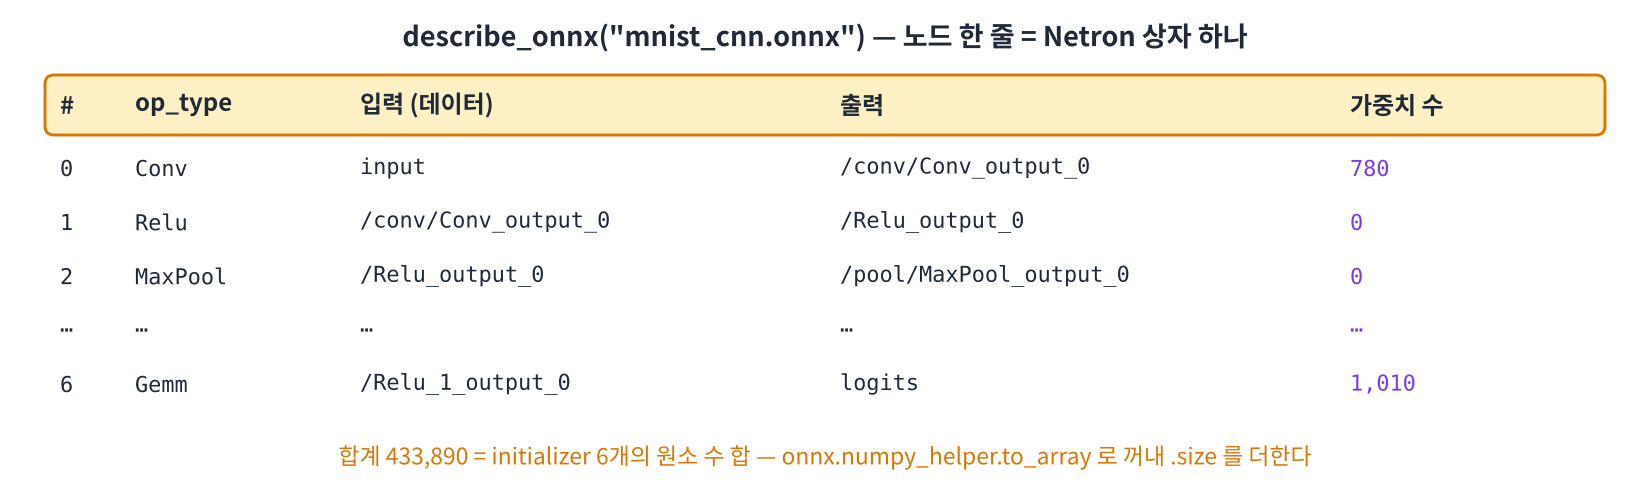

In [ ]:
#@title 🖼 그림 — describe_onnx — 노드 한 줄 = Netron 상자 하나
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f3_describe.png", embed=True, width=860))

**문제 3-3** 2교시와 3교시를 합쳐 **그래프 요약 표**를 돌려주는 `describe_onnx(path)` 를 완성하세요. 한 줄 = 노드 하나, 열은 `op_type` · `data_in`(데이터 입력) · `out`(출력) · `params`(이 노드의 가중치 원소 수) · `attrs`(속성) 입니다.

In [ ]:
def describe_onnx(path):
    model = onnx.load(path)
    gr = model.graph
    W_ = {t.name: onnx.numpy_helper.to_array(t) for t in gr.initializer}
    rows = []
    for n in gr.node:
        rows.append({
            "op_type": n.op_type,
            "data_in": [x for x in n.input if x and x not in W_],
            "out": list(n.output),
            "params": sum(W_[x].size for x in n.input if x in ____),
            "attrs": attrs_of(n),
        })
    return pd.DataFrame(rows)

df = describe_onnx("mnist_cnn.onnx")
display(df)
print("노드", len(df), "| 가중치 합계", f"{df.params.____():,}")

In [ ]:
assert len(df) == 7 and df.params.sum() == 433_890 and df.params.tolist() == [780, 0, 0, 0, 432_100, 0, 1_010]
print("✅ describe_onnx 완성 — 8교시와 Day 3 이후에 계속 씁니다")

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACmRlZiBkZXNjcmliZV9vbm54KHBhdGgpOgogICAgbW9kZWwgPSBvbm54"
    "LmxvYWQocGF0aCkKICAgIGdyID0gbW9kZWwuZ3JhcGgKICAgIFdfID0ge3QubmFtZTogb25ueC5udW1weV9oZWxw"
    "ZXIudG9fYXJyYXkodCkgZm9yIHQgaW4gZ3IuaW5pdGlhbGl6ZXJ9CiAgICByb3dzID0gW10KICAgIGZvciBuIGlu"
    "IGdyLm5vZGU6CiAgICAgICAgcm93cy5hcHBlbmQoewogICAgICAgICAgICAib3BfdHlwZSI6IG4ub3BfdHlwZSwK"
    "ICAgICAgICAgICAgImRhdGFfaW4iOiBbeCBmb3IgeCBpbiBuLmlucHV0IGlmIHggYW5kIHggbm90IGluIFdfXSwK"
    "ICAgICAgICAgICAgIm91dCI6IGxpc3Qobi5vdXRwdXQpLAogICAgICAgICAgICAicGFyYW1zIjogc3VtKFdfW3hd"
    "LnNpemUgZm9yIHggaW4gbi5pbnB1dCBpZiB4IGluIFdfKSwKICAgICAgICAgICAgImF0dHJzIjogYXR0cnNfb2Yo"
    "biksCiAgICAgICAgfSkKICAgIHJldHVybiBwZC5EYXRhRnJhbWUocm93cykKCmRmID0gZGVzY3JpYmVfb25ueCgi"
    "bW5pc3RfY25uLm9ubngiKQpkaXNwbGF5KGRmKQpwcmludCgi64W465OcIiwgbGVuKGRmKSwgInwg6rCA7KSR7LmY"
    "IO2VqeqzhCIsIGYie2RmLnBhcmFtcy5zdW0oKTosfSIpCgrwn5KhIO2VtOyEpApwYXJhbXMg7Je07J20IERheSAx"
    "IDbqtZDsi5wg6re466a87J2YIOuztOudvOyDiSDsiKvsnpAgKDc4MCDCtyA0MzIsMTAwIMK3IDEsMDEwKSDsmYAg"
    "6rCZ7Iq164uI64ukLgpgaWYgeGAg64qUIOu5iCDsnbTrpoTsnYQg6rGw66W06riwIOychO2VnCDqsoMg4oCUIOyd"
    "vOu2gCDrhbjrk5zripQgJ+ydtCDsnoXroKXsnYAg7IOd6561JyDsnYQg67mIIOusuOyekOyXtOuhnCDtkZzsi5zt"
    "lanri4jri6Qu"
).decode("utf-8"))

### 🔁 바꿔보기 — SafetyNet 을 표로 보면?

Day 1 미니 프로젝트의 SafetyNet 을 내보내 같은 표로 봅니다. PyTorch 파라미터 수와 ONNX `params` 합계를 비교해 보세요. **왜 다를까요?**

In [ ]:
safety = make_safety()
torch.onnx.export(safety, torch.randn(1, 3, 64, 64), "safety.onnx", input_names=["input"], output_names=["logits"], **EXPORT_KW)
df_s = describe_onnx("safety.onnx")
display(df_s[["op_type", "params", "attrs"]])
print("PyTorch 파라미터", sum(p.numel() for p in safety.parameters()), "| ONNX 가중치 합계", df_s.params.sum())

> 차이 = BatchNorm 의 γ · β (8 + 8 + 16 + 16 = **48개**). Day 1 에서 본 **Conv-BN 합치기** 때문에 BN 의 숫자가 Conv 의 weight · bias 안으로 녹아 들어가 따로 세어지지 않습니다. 평균 · 분산 (running_mean · var) 은 원래 학습 파라미터가 아니라 세지 않습니다.

#### ⚠️ 자주 하는 실수

- `to_array(t).shape` 를 개수로 착각 → 개수는 `.size` (모든 축 곱).
- `onnx.helper.get_attribute_value` 를 빼고 `a.ints` · `a.i` 를 직접 읽음 → 속성 종류마다 필드가 달라 헷갈립니다. 도우미 함수를 쓰세요.
- `display(df)` 대신 `print(df)` → 열이 잘려 보일 수 있습니다.

#### 📌 3교시 정리

- 가중치 = `numpy_helper.to_array(initializer)`, 속성 = `helper.get_attribute_value(attribute)`.
- `describe_onnx(path)` = 노드마다 종류 · 입출력 · 가중치 수 · 속성을 한 줄로. **Netron 을 코드로 만든 것.**
- ONNX 가중치 수 ≠ PyTorch 파라미터 수일 수 있다 — Conv-BN 합치기.

## 4교시 — opset · checker · shape_inference

ONNX 파일을 다룰 때 쓰는 세 가지 도구입니다.

| 도구 | 하는 일 | 비유 |
|---|---|---|
| **opset** | 파일이 쓰는 '연산 사전' 의 판 번호 | 사전의 몇 판으로 썼나 |
| **checker** | 파일이 규칙에 맞게 만들어졌는지 검사 | 맞춤법 검사기 |
| **shape_inference** | 중간 화살표마다 shape 를 계산해 적어 넣기 | 도면에 치수 적기 |

> 🎬 **애니메이션** [D2-4 opset 사전 · checker](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

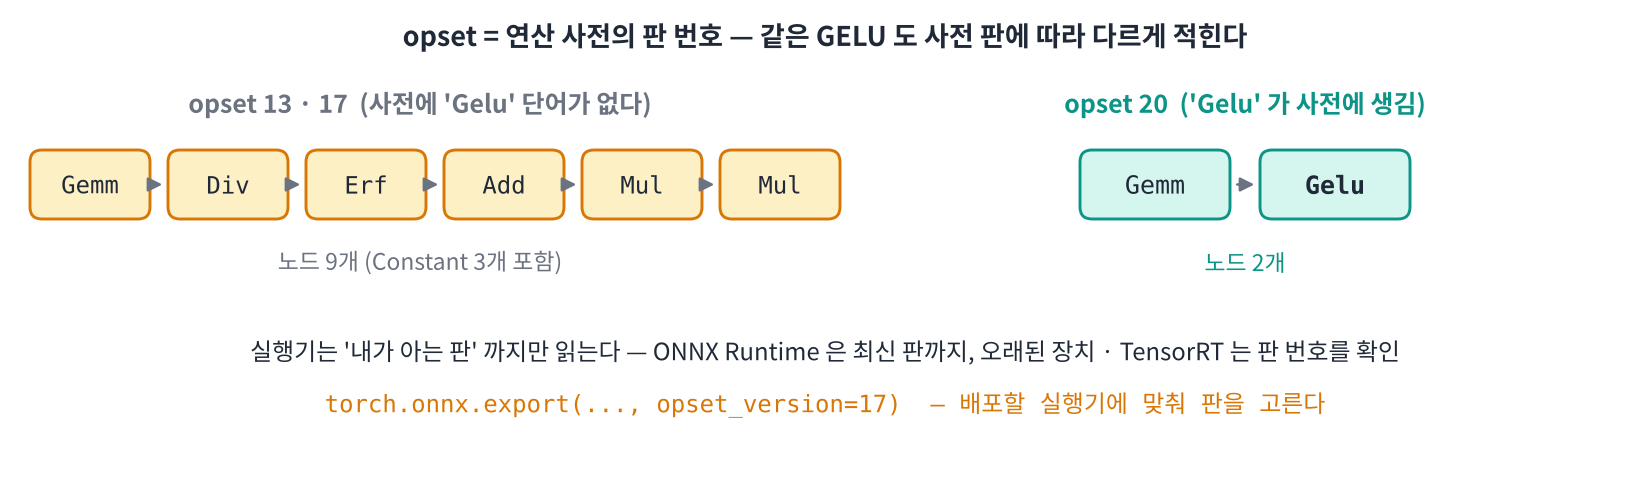

In [ ]:
#@title 🖼 그림 — opset = 연산 사전의 판 번호 — GELU 의 두 가지 모습
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f4_opset.png", embed=True, width=860))

**문제 4-1** GELU 활성화 함수를 쓰는 작은 모델을 **opset 13** 과 **opset 20** 으로 각각 내보내고 노드 종류를 비교하세요. `torch.onnx.export` 의 `opset_version=` 옵션으로 판 번호를 정합니다.

In [ ]:
gelu_net = nn.Sequential(nn.Linear(4, 4), nn.GELU()).eval()
ops_by_opset = {}
for v in [13, 20]:
    path = f"gelu_op{v}.onnx"
    torch.onnx.export(gelu_net, torch.randn(1, 4), path, opset_version=____, **EXPORT_KW)
    ops_by_opset[v] = [n.op_type for n in onnx.load(path).graph.node]
    print(f"opset {v}: {len(ops_by_opset[v])}개", ops_by_opset[v])

In [ ]:
assert "Gelu" in ops_by_opset[20] and "Gelu" not in ops_by_opset[13] and "Erf" in ops_by_opset[13]
print("✅ 같은 계산 — opset 13 은 Erf 로 풀어 쓰고, opset 20 은 Gelu 한 단어")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmdlbHVfbmV0ID0gbm4uU2VxdWVudGlhbChubi5MaW5lYXIoNCwgNCks"
    "IG5uLkdFTFUoKSkuZXZhbCgpCm9wc19ieV9vcHNldCA9IHt9CmZvciB2IGluIFsxMywgMjBdOgogICAgcGF0aCA9"
    "IGYiZ2VsdV9vcHt2fS5vbm54IgogICAgdG9yY2gub25ueC5leHBvcnQoZ2VsdV9uZXQsIHRvcmNoLnJhbmRuKDEs"
    "IDQpLCBwYXRoLCBvcHNldF92ZXJzaW9uPXYsICoqRVhQT1JUX0tXKQogICAgb3BzX2J5X29wc2V0W3ZdID0gW24u"
    "b3BfdHlwZSBmb3IgbiBpbiBvbm54LmxvYWQocGF0aCkuZ3JhcGgubm9kZV0KICAgIHByaW50KGYib3BzZXQge3Z9"
    "OiB7bGVuKG9wc19ieV9vcHNldFt2XSl96rCcIiwgb3BzX2J5X29wc2V0W3ZdKQoK8J+SoSDtlbTshKQKR0VMVSh4"
    "KSA9IHggwrcgwr0gKDEgKyBlcmYoeCAvIOKImjIpKS4gb3BzZXQgMjAg7IKs7KCE7JeQ64qUICdHZWx1JyDrnbzr"
    "ipQg64uo7Ja06rCAIOyDneqyqCDtlZwg64W465Oc66GcIOyggeqzoCwK6re4IOyghCDtjJDsl5DripQg64uo7Ja0"
    "6rCAIOyXhuyWtCBEaXYgwrcgRXJmIMK3IEFkZCDCtyBNdWwg66GcIO2SgOyWtCDslIHri4jri6QuIOqysOqzvOuK"
    "lCDqsJnsirXri4jri6QuCuyLpO2Wieq4sCAo7Yq57Z6IIOyYpOuemOuQnCDsnqXsuZggwrcgVGVuc29yUlQg67KE"
    "7KCEKSDqsIAg7JWE64qUIO2MkOuztOuLpCDrhpLsnYAgb3BzZXQg7Jy866GcIOuCtOuztOuCtOuptCAn66qo66W0"
    "64qUIOuLqOyWtCcg7Jik66WY6rCAIOuCqeuLiOuLpC4="
).decode("utf-8"))

In [ ]:
# 두 파일의 결과가 정말 같은지 — 입력 이름은 sess 에서 읽는다
xg = np.random.randn(1, 4).astype(np.float32)
outs = {}
for v in [13, 20]:
    s = ort.InferenceSession(f"gelu_op{v}.onnx", providers=["CPUExecutionProvider"])
    outs[v] = s.run(None, {s.get_inputs()[0].name: xg})[0]
print("opset 13 vs 20 최대 차이:", np.abs(outs[13] - outs[20]).max())
print("mnist_cnn.onnx 의 opset (기본값):", onnx.load("mnist_cnn.onnx").opset_import[0].version)

### checker — 고장 난 파일 찾기

일부러 파일을 망가뜨려 봅니다. 두 번째 노드(Relu) 의 input 이름을 존재하지 않는 `"nope"` 로 바꾸면, 화살표가 끊깁니다.

In [ ]:
bad = onnx.load("mnist_cnn.onnx")
bad.graph.node[1].input[0] = "nope"                  # Relu 의 입력 화살표를 끊는다
try:
    onnx.checker.check_model(bad)
except Exception as e:
    print("checker →", type(e).__name__, ":", str(e).split("\n")[0])
try:
    ort.InferenceSession(bad.SerializeToString(), providers=["CPUExecutionProvider"])
except Exception as e:
    print("ORT     →", str(e)[:150])

**문제 4-2** 고장 난 `bad` 를 고치세요. Relu 의 input 은 **바로 앞 노드(Conv) 의 output 이름**이어야 합니다 (2교시 화살표 규칙). 숫자나 이름을 직접 쓰지 말고 `bad.graph.node[0]` 에서 읽어 오세요.

In [ ]:
bad.graph.node[1].input[0] = bad.graph.node[0].____[0]
onnx.checker.check_model(bad)
print("고친 이름:", bad.graph.node[1].input[0])

In [ ]:
s_fix = ort.InferenceSession(bad.SerializeToString(), providers=["CPUExecutionProvider"])
assert np.allclose(s_fix.run(None, {"input": x0})[0], y_pt, atol=1e-5); print("✅ checker 통과 · 결과도 원래대로")

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmJhZC5ncmFwaC5ub2RlWzFdLmlucHV0WzBdID0gYmFkLmdyYXBoLm5v"
    "ZGVbMF0ub3V0cHV0WzBdCm9ubnguY2hlY2tlci5jaGVja19tb2RlbChiYWQpCnByaW50KCLqs6DsuZwg7J2066aE"
    "OiIsIGJhZC5ncmFwaC5ub2RlWzFdLmlucHV0WzBdKQoK8J+SoSDtlbTshKQKY2hlY2tlciDripQgJ+qzhOyCsCDs"
    "iJzshJzrjIDroZwg7KCV66Cs65CY7Ja0IOyeiOyWtOyVvCDtlZzri6QgKHRvcG9sb2dpY2FsbHkgc29ydGVkKScg"
    "64qUIOq3nOy5meycvOuhnCDrgYrquLQg7ZmU7IK07ZGc66W8IOywvuyKteuLiOuLpC4KY2hlY2tlciDthrXqs7wg"
    "PSDtmJXsi53snbQg66ee64uk64qUIOucuy4g6rKw6rO86rCAIOunnuuKlOyngOuKlCDsl6zsoITtnoggYWxsY2xv"
    "c2Ug66GcIO2ZleyduO2VqeuLiOuLpC4="
).decode("utf-8"))

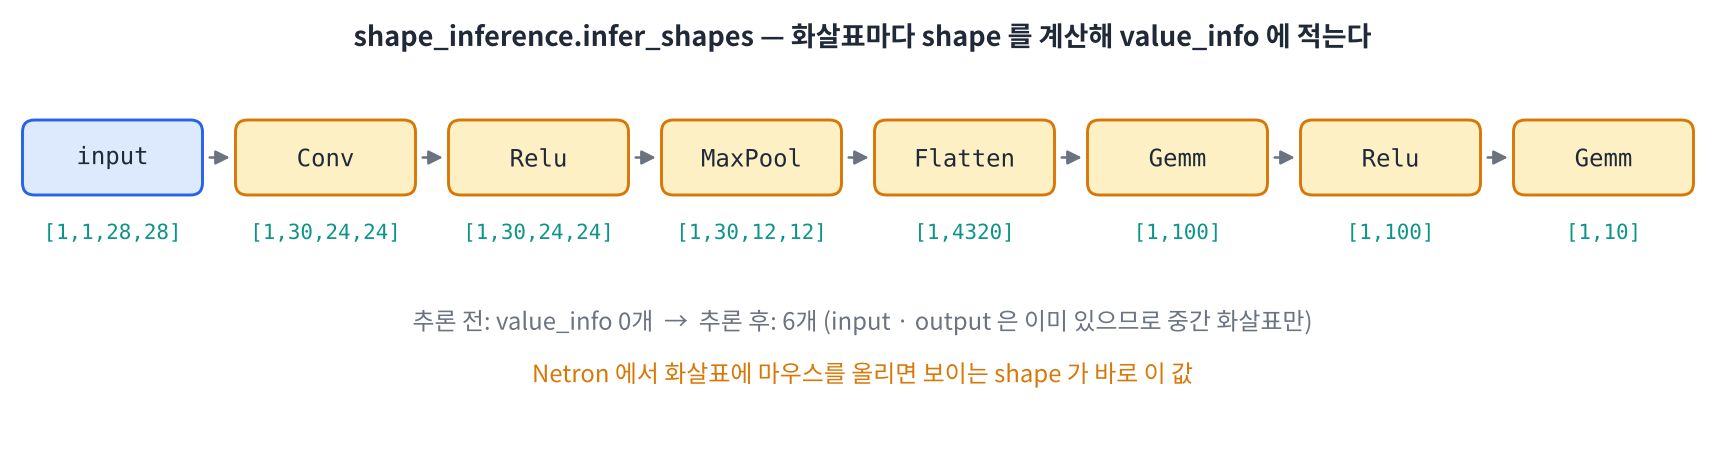

In [ ]:
#@title 🖼 그림 — shape_inference — 화살표마다 shape 를 계산해 적는다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f4_shapes.png", embed=True, width=880))

**문제 4-3** `onnx.shape_inference.infer_shapes(m)` 은 중간 화살표의 shape 를 계산해 `graph.value_info` 에 적은 **새 모델**을 돌려줍니다. 추론 전 · 후의 `value_info` 개수를 비교하고, 화살표 이름 → shape 표를 출력하세요 (2-2 의 `shape_of` 사용).

In [ ]:
print("추론 전 value_info:", len(m.graph.value_info))
mi = onnx.shape_inference.____(m)
shapes = {vi.name: shape_of(vi) for vi in mi.graph.____}
print("추론 후 value_info:", len(shapes))
for k, v in shapes.items():
    print(" ", k.ljust(26), v)

In [ ]:
assert len(shapes) == 6 and shapes["/pool/MaxPool_output_0"] == [1, 30, 12, 12] and [1, 4320] in shapes.values()
print("✅ Day 1 6교시 그림의 shape (24 → 12 → 4320) 를 코드로 얻었다")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACnByaW50KCLstpTroaAg7KCEIHZhbHVlX2luZm86IiwgbGVuKG0uZ3Jh"
    "cGgudmFsdWVfaW5mbykpCm1pID0gb25ueC5zaGFwZV9pbmZlcmVuY2UuaW5mZXJfc2hhcGVzKG0pCnNoYXBlcyA9"
    "IHt2aS5uYW1lOiBzaGFwZV9vZih2aSkgZm9yIHZpIGluIG1pLmdyYXBoLnZhbHVlX2luZm99CnByaW50KCLstpTr"
    "oaAg7ZuEIHZhbHVlX2luZm86IiwgbGVuKHNoYXBlcykpCmZvciBrLCB2IGluIHNoYXBlcy5pdGVtcygpOgogICAg"
    "cHJpbnQoIiAiLCBrLmxqdXN0KDI2KSwgdikKCvCfkqEg7ZW07ISkCu2ZlOyCtO2RnCA36rCcIOykkSBpbnB1dCDC"
    "tyBvdXRwdXQg7J2AIOydtOuvuCBzaGFwZSDqsIAg7J6I7Ja0IOykkeqwhCDtmZTsgrTtkZwgNuqwnOunjCDssYTs"
    "m4zsp5Hri4jri6QuCicoMjgg4oiSIDUpIC8gMSArIDEgPSAyNCcg6rCZ7J2AIOqzhOyCsOydhCBDb252IOyGjeyE"
    "sSAoa2VybmVsX3NoYXBlIMK3IHN0cmlkZXMgwrcgcGFkcykg7Jy866GcIO2VtCDspI3ri4jri6Qg4oCUIDPqtZDs"
    "i5wgYXR0cnMg6rCAIOyXrOq4sCDsk7DsnoXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `infer_shapes(m)` 만 하고 `m.graph.value_info` 를 봄 → 결과는 **새 모델**(`mi`) 에 있습니다.
- opset 을 너무 높게 → 실행기 오류 `... opset ... is not supported` 류. 배포할 실행기의 지원 판부터 확인.
- checker 통과를 '결과가 맞다' 로 착각 → 형식 검사일 뿐. **allclose 는 따로.**

#### 📌 4교시 정리

- **opset** = 연산 사전 판 번호. `opset_version=` 으로 정한다. 같은 계산도 판에 따라 노드가 다르다 (GELU 9개 vs 2개).
- **checker** = 규칙 검사 (끊긴 화살표 · 순서). **shape_inference** = 중간 shape 채우기.
- 세 도구 모두 '결과가 맞는지' 는 말해 주지 않는다 → allclose.

## 5교시 — 배치 크기 자유롭게: `dynamic_axes`

어제 5교시: 고정 shape 파일에 배치 4를 넣으면 `Got: 4 Expected: 1`. 오늘은 **"이 축은 크기가 바뀔 수 있다"** 고 export 때 알려 줍니다.

> 🎬 **애니메이션** [D2-5 dynamic_axes — 배치 축 열기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

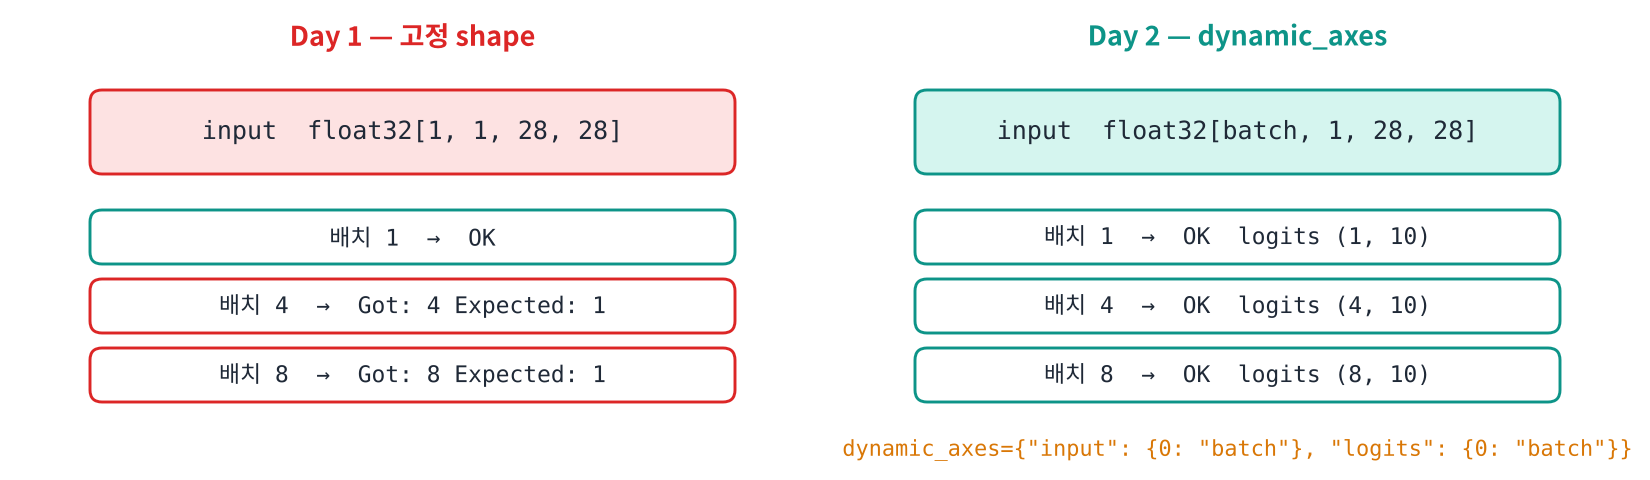

In [ ]:
#@title 🖼 그림 — 고정 shape vs dynamic_axes
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f5_dynamic.png", embed=True, width=860))

**문제 5-1** `dynamic_axes` 는 `{이름: {축 번호: 축 이름}}` 딕셔너리입니다. 입력 `input` 과 출력 `logits` 의 **0번 축**(배치) 에 `"batch"` 라는 이름을 붙여 `mnist_cnn_dyn.onnx` 로 내보내세요.

In [ ]:
torch.onnx.export(cnn, torch.zeros(1, 1, 28, 28), "mnist_cnn_dyn.onnx",
                  input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {____: "batch"}, "logits": {____: "batch"}}, **EXPORT_KW)
sess_dyn = ort.InferenceSession("mnist_cnn_dyn.onnx", providers=["CPUExecutionProvider"])
print("입력", sess_dyn.get_inputs()[0].shape, "| 출력", sess_dyn.get_outputs()[0].shape)
for b in [1, 4, 8]:
    print("배치", b, "→", sess_dyn.run(None, {"input": np.random.rand(b, 1, 28, 28).astype(np.float32)})[0].shape)

In [ ]:
assert sess_dyn.get_inputs()[0].shape == ["batch", 1, 28, 28] and sess_dyn.get_outputs()[0].shape == ["batch", 10]
print("✅ 첫 축이 숫자 1 대신 이름 'batch' — 2-2 의 dim_param")

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACnRvcmNoLm9ubnguZXhwb3J0KGNubiwgdG9yY2guemVyb3MoMSwgMSwg"
    "MjgsIDI4KSwgIm1uaXN0X2Nubl9keW4ub25ueCIsCiAgICAgICAgICAgICAgICAgIGlucHV0X25hbWVzPVsiaW5w"
    "dXQiXSwgb3V0cHV0X25hbWVzPVsibG9naXRzIl0sCiAgICAgICAgICAgICAgICAgIGR5bmFtaWNfYXhlcz17Imlu"
    "cHV0IjogezA6ICJiYXRjaCJ9LCAibG9naXRzIjogezA6ICJiYXRjaCJ9fSwgKipFWFBPUlRfS1cpCnNlc3NfZHlu"
    "ID0gb3J0LkluZmVyZW5jZVNlc3Npb24oIm1uaXN0X2Nubl9keW4ub25ueCIsIHByb3ZpZGVycz1bIkNQVUV4ZWN1"
    "dGlvblByb3ZpZGVyIl0pCnByaW50KCLsnoXroKUiLCBzZXNzX2R5bi5nZXRfaW5wdXRzKClbMF0uc2hhcGUsICJ8"
    "IOy2nOugpSIsIHNlc3NfZHluLmdldF9vdXRwdXRzKClbMF0uc2hhcGUpCmZvciBiIGluIFsxLCA0LCA4XToKICAg"
    "IHByaW50KCLrsLDsuZgiLCBiLCAi4oaSIiwgc2Vzc19keW4ucnVuKE5vbmUsIHsiaW5wdXQiOiBucC5yYW5kb20u"
    "cmFuZChiLCAxLCAyOCwgMjgpLmFzdHlwZShucC5mbG9hdDMyKX0pWzBdLnNoYXBlKQoK8J+SoSDtlbTshKQK642U"
    "66+4IOyeheugpeydgCDsl6zsoITtnogg67Cw7LmYIDEg7J207KeA66eMLCBkeW5hbWljX2F4ZXMg6rCAICcw67KI"
    "IOy2leydgCDsnbTrpoTsnbwg67+QIOyIq+yekOuhnCDqtbPtnojsp4Ag66eI6528JyDqs6Ag7JWM66CkIOykjeuL"
    "iOuLpC4K64W465OcIOq1rOyEseydgCDqs6DsoJUg67KE7KCE6rO8IOqwmeyKteuLiOuLpCAoZGVzY3JpYmVfb25u"
    "eCDroZwg67mE6rWQ7ZW0IOuztOyEuOyalCku"
).decode("utf-8"))

**문제 5-2** 이제 **100장을 한 번에** 넣을 수 있습니다. `digits (100, 28, 28) uint8` 을 `(100, 1, 28, 28) float32` 0~1 로 바꾸고, 한 번의 `run` 으로 예측해 정확도를 구하세요.

In [ ]:
X = (digits.astype(np.float32) / 255)[:, ____]            # (100, 28, 28) → (100, 1, 28, 28)
pred = sess_dyn.run(None, {"input": X})[0].argmax(____)
acc = (pred == labels).mean()
print(X.shape, "→ 정확도", acc)

In [ ]:
with torch.no_grad():
    ref = cnn(torch.from_numpy(X)).argmax(1).numpy()
assert X.shape == (100, 1, 28, 28) and (pred == ref).all() and acc >= 0.95; print("✅ 한 번에 100장 — PyTorch 예측과 100장 모두 같다")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSAClggPSAoZGlnaXRzLmFzdHlwZShucC5mbG9hdDMyKSAvIDI1NSlbOiwg"
    "Tm9uZV0gICAgICAgICAgICAjICgxMDAsIDI4LCAyOCkg4oaSICgxMDAsIDEsIDI4LCAyOCkKcHJlZCA9IHNlc3Nf"
    "ZHluLnJ1bihOb25lLCB7ImlucHV0IjogWH0pWzBdLmFyZ21heCgxKQphY2MgPSAocHJlZCA9PSBsYWJlbHMpLm1l"
    "YW4oKQpwcmludChYLnNoYXBlLCAi4oaSIOygle2ZleuPhCIsIGFjYykKCvCfkqEg7ZW07ISkCls6LCBOb25lXSA9"
    "IDHrsogg7J6Q66as7JeQIOyxhOuEkCDstpUg7LaU6rCALiBhcmdtYXgoMSkgPSDqsIEg7KSEKOyCrOynhCnrp4jr"
    "i6QgMTDqsJwg7KSRIOqwgOyepSDtgbAg7Lm4IOKAlCBhcmdtYXgoKSDrp4wg7JOw66m0IDEwMDDqsJwg7KCE7LK0"
    "7JeQ7IScIO2VmOuCmOunjCDrgpjsmLXri4jri6Qu"
).decode("utf-8"))

### 🔁 바꿔보기 — 1장씩 100번 vs 100장 1번

같은 100장을 두 가지 방법으로 실행해 시간을 비교합니다. (시간 재는 법은 Day 3 에 제대로 배웁니다 — 오늘은 느낌만.)

In [ ]:
sess_dyn.run(None, {"input": X[:1]})                       # 첫 실행은 준비 시간이 섞이므로 한 번 버린다
t = time.perf_counter()
for i in range(100):
    sess_dyn.run(None, {"input": X[i:i + 1]})
t_each = (time.perf_counter() - t) * 1000
t = time.perf_counter()
sess_dyn.run(None, {"input": X})
t_batch = (time.perf_counter() - t) * 1000
print(f"1장씩 100번 {t_each:.1f} ms | 100장 1번 {t_batch:.1f} ms → {t_each / t_batch:.1f}배")

**문제 5-3** **dynamic 은 약속일 뿐** — 높이 · 너비(2 · 3번 축) 까지 자유롭게 내보내 봅니다. export 는 성공하지만, 32×32 사진을 넣으면 실행 중 오류가 납니다. 오류 메시지에서 **어떤 종류의 노드가 실패했는지** 찾아 `failed_op` 에 쓰세요.

In [ ]:
torch.onnx.export(cnn, torch.zeros(1, 1, 28, 28), "mnist_cnn_hw.onnx", input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch", 2: "height", 3: "width"}, "logits": {0: "batch"}}, **EXPORT_KW)
s_hw = ort.InferenceSession("mnist_cnn_hw.onnx", providers=["CPUExecutionProvider"])
print("입력 shape:", s_hw.get_inputs()[0].shape)
try:
    s_hw.run(None, {"input": np.zeros((1, 1, 32, 32), np.float32)})
except Exception as e:
    print(str(e)[:220])
failed_op = "____"

In [ ]:
assert failed_op == "Gemm"; print("✅ Conv · Pool 은 어떤 크기든 되지만, Flatten 뒤 Gemm 은 정확히 4320 개를 원한다")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACnRvcmNoLm9ubnguZXhwb3J0KGNubiwgdG9yY2guemVyb3MoMSwgMSwg"
    "MjgsIDI4KSwgIm1uaXN0X2Nubl9ody5vbm54IiwgaW5wdXRfbmFtZXM9WyJpbnB1dCJdLCBvdXRwdXRfbmFtZXM9"
    "WyJsb2dpdHMiXSwKICAgICAgICAgICAgICAgICAgZHluYW1pY19heGVzPXsiaW5wdXQiOiB7MDogImJhdGNoIiwg"
    "MjogImhlaWdodCIsIDM6ICJ3aWR0aCJ9LCAibG9naXRzIjogezA6ICJiYXRjaCJ9fSwgKipFWFBPUlRfS1cpCnNf"
    "aHcgPSBvcnQuSW5mZXJlbmNlU2Vzc2lvbigibW5pc3RfY25uX2h3Lm9ubngiLCBwcm92aWRlcnM9WyJDUFVFeGVj"
    "dXRpb25Qcm92aWRlciJdKQpwcmludCgi7J6F66ClIHNoYXBlOiIsIHNfaHcuZ2V0X2lucHV0cygpWzBdLnNoYXBl"
    "KQp0cnk6CiAgICBzX2h3LnJ1bihOb25lLCB7ImlucHV0IjogbnAuemVyb3MoKDEsIDEsIDMyLCAzMiksIG5wLmZs"
    "b2F0MzIpfSkKZXhjZXB0IEV4Y2VwdGlvbiBhcyBlOgogICAgcHJpbnQoc3RyKGUpWzoyMjBdKQpmYWlsZWRfb3Ag"
    "PSAiR2VtbSIKCvCfkqEg7ZW07ISkCjMyw5czMiDihpIgQ29udiAyOMOXMjgg4oaSIFBvb2wgMTTDlzE0IOKGkiBG"
    "bGF0dGVuIDMwwrcxNMK3MTQgPSA1ODgwIOqwnC4gZmMxIOydgCA0MzIwIOqwnOulvCDrsJvrj4TroZ0g7ZWZ7Iq1"
    "65CcIEdlbW0g7J206528IOyLpO2MqO2VqeuLiOuLpC4KZHluYW1pY19heGVzIOuKlCAn7J20IOy2leydgCDrsJTr"
    "gJQg7IiYIOyeiOuLpCcg64qUIO2RnOyLnOydvCDrv5AsIOuqqOuNuOydtCDsi6TsoJzroZwg6re4IO2BrOq4sOul"
    "vCDsspjrpqztlaAg7IiYIOyeiOuKlOyngOuKlCDrqqjrjbgg6rWs7KGw6rCAIOygle2VqeuLiOuLpC4K6re4656Y"
    "7IScIOydtCDqs7zsoJXsl5DshJzripQg67Cw7LmYIOy2leunjCDsnpDsnKDroa3qsowg7ZWp64uI64ukLg=="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `dynamic_axes={"input": [0]}` 처럼 리스트로 → 동작은 하지만 축 이름이 자동으로 붙어 읽기 어렵습니다. `{0: "batch"}` 처럼 이름을 주세요.
- `dynamic_axes` 의 키를 `input_names` 와 다르게 씀 (`"x"` 등) → 이름이 맞지 않아 적용되지 않습니다.
- 출력 쪽을 빼먹음 → 이 버전에서는 자동으로 따라오기도 하지만, **입력 · 출력 둘 다** 적는 습관을.

#### 📌 5교시 정리

- `dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}` → shape 의 첫 축이 이름 `'batch'`.
- 100장을 한 번에 `run` — 1장씩 100번보다 빠르다 (Day 3 에서 정확히 잰다).
- dynamic 은 약속일 뿐 — 모델이 처리 못 하는 크기는 **실행 중** 오류 (Flatten → Gemm).

## 6교시 — 조용히 틀리는 export 3가지: if · NumPy · 고정 배치

지금까지 export 는 늘 성공했고 결과도 맞았습니다. 그런데 **export 가 성공했는데 결과가 틀리는** 경우가 있습니다. 오류 메시지가 없어 가장 위험합니다. 원인은 하나 — **export 는 더미 입력으로 실제 실행된 길만 녹화한다** (Day 1 2교시).

> 🎬 **애니메이션** [D2-6 녹화되는 길 · 굳는 값](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 오늘의 무기 — `verify()` · `export_warn()`

여러 입력으로 PyTorch 와 ONNX 를 비교하는 함수, export 중 나온 **TracerWarning** 만 골라 보여 주는 함수입니다. 환경 셀에서 경고를 모두 숨겼기 때문에, 이 함수로 필요한 경고만 다시 봅니다.

In [ ]:
def verify(model, path, cases, atol=1e-4):
    """cases = {이름: 입력 배열}. PyTorch 와 ONNX Runtime 결과를 비교해 표로 출력하고, 모두 같으면 True"""
    s = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    name = s.get_inputs()[0].name
    ok_all = True
    for k, x in cases.items():
        try:
            with torch.no_grad():
                ref = model(torch.from_numpy(x)).numpy()
        except Exception as e:
            ok_all = False
            print("❌", k.ljust(14), "PyTorch 도 실행 오류:", str(e).split("\n")[0][:80])
            continue
        try:
            out = s.run(None, {name: x})[0]
            diff = float(np.abs(out - ref).max()) if out.shape == ref.shape else float("inf")
            ok = diff <= atol
            msg = f"최대 차이 {diff:.2e}" if out.shape == ref.shape else f"shape 다름 {out.shape} vs {ref.shape}"
        except Exception as e:
            ok, msg = False, "실행 오류: " + str(e).split("Status Message:")[-1].strip()[:90]
        ok_all &= ok
        print(("✅" if ok else "❌"), k.ljust(14), msg)
    return ok_all

def export_warn(model, dummy, path, **kw):
    """export 하면서 TracerWarning 만 골라 출력한다"""
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        torch.onnx.export(model, dummy, path, **kw, **EXPORT_KW)
    for x in w:
        if x.category.__name__ == "TracerWarning":
            print("⚠️ TracerWarning:", str(x.message).split(".")[0])
    print("export 완료 →", path, [n.op_type for n in onnx.load(path).graph.node])

### ① 파이썬 `if` — 한쪽 길만 녹화된다

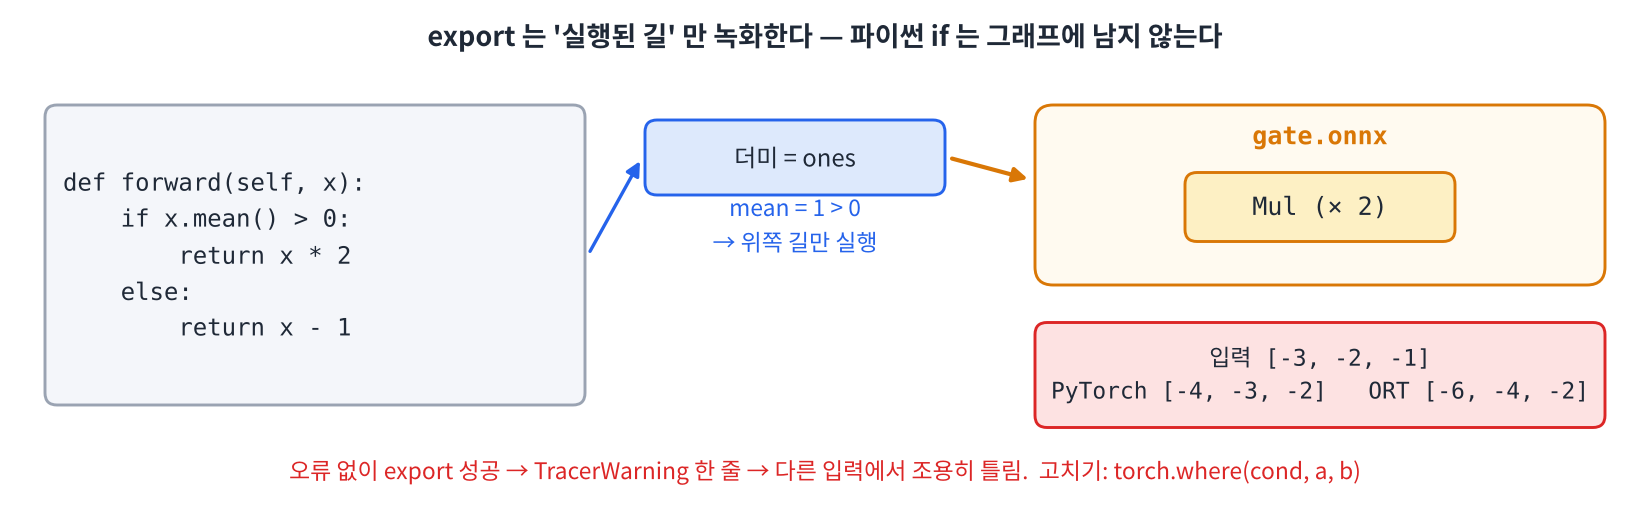

In [ ]:
#@title 🖼 그림 — export 는 실행된 길만 녹화 — if 는 그래프에 남지 않는다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f6_trace_if.png", embed=True, width=860))

In [ ]:
class Gate(nn.Module):
    """평균이 양수면 2배, 아니면 1을 뺀다"""
    def forward(self, x):
        if x.mean() > 0:
            return x * 2
        else:
            return x - 1

gate = Gate()
export_warn(gate, torch.ones(1, 3), "gate.onnx", input_names=["input"], output_names=["output"])
cases_gate = {"양수 [1,2,3]": np.array([[1., 2., 3.]], np.float32), "음수 [-3,-2,-1]": np.array([[-3., -2., -1.]], np.float32)}
verify(gate, "gate.onnx", cases_gate)

**문제 6-1** 그래프 노드는 `Mul` 하나뿐 — `else` 쪽은 녹화되지 않았습니다. **두 길을 모두 그래프에 넣으려면** `torch.where(조건, 참일 때, 거짓일 때)` 를 씁니다. 조건을 채워 `GateFix` 를 완성하세요.

In [ ]:
class GateFix(nn.Module):
    def forward(self, x):
        return torch.where(____, x * 2, x - 1)

gate_fix = GateFix()
export_warn(gate_fix, torch.ones(1, 3), "gate_fix.onnx", input_names=["input"], output_names=["output"])
ok_gate = verify(gate_fix, "gate_fix.onnx", cases_gate)

In [ ]:
assert ok_gate and "Where" in [n.op_type for n in onnx.load("gate_fix.onnx").graph.node]; print("✅ 두 길이 모두 그래프에 — Where 노드")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmNsYXNzIEdhdGVGaXgobm4uTW9kdWxlKToKICAgIGRlZiBmb3J3YXJk"
    "KHNlbGYsIHgpOgogICAgICAgIHJldHVybiB0b3JjaC53aGVyZSh4Lm1lYW4oKSA+IDAsIHggKiAyLCB4IC0gMSkK"
    "CmdhdGVfZml4ID0gR2F0ZUZpeCgpCmV4cG9ydF93YXJuKGdhdGVfZml4LCB0b3JjaC5vbmVzKDEsIDMpLCAiZ2F0"
    "ZV9maXgub25ueCIsIGlucHV0X25hbWVzPVsiaW5wdXQiXSwgb3V0cHV0X25hbWVzPVsib3V0cHV0Il0pCm9rX2dh"
    "dGUgPSB2ZXJpZnkoZ2F0ZV9maXgsICJnYXRlX2ZpeC5vbm54IiwgY2FzZXNfZ2F0ZSkKCvCfkqEg7ZW07ISkCnRv"
    "cmNoLndoZXJlIOuKlCDrkZAg6rKw6rO866W8IOuqqOuRkCDqs4TsgrDtlZwg65KkIOyhsOqxtOycvOuhnCDqs6Dr"
    "poXri4jri6Qg4oCUIFJlZHVjZU1lYW4gwrcgR3JlYXRlciDCtyBNdWwgwrcgU3ViIMK3IFdoZXJlIOuFuOuTnOqw"
    "gCDsg53quYHri4jri6QuClRyYWNlcldhcm5pbmcg64+EIOyCrOudvOyhjOyKteuLiOuLpC4gJ0NvbnZlcnRpbmcg"
    "YSB0ZW5zb3IgdG8gYSBQeXRob24gYm9vbGVhbicg6rK96rOg6rCAIOuztOydtOuptCDsnbQg66y47KCc66W8IOyd"
    "mOyLrO2VmOyEuOyalC4="
).decode("utf-8"))

### ② NumPy · `.item()` · `float()` — 그때의 값이 상수로 굳는다

In [ ]:
class Center(nn.Module):
    """센서 값에서 평균을 빼 0 근처로 맞춘다"""
    def forward(self, x):
        m = float(np.mean(x.detach().numpy()))     # NumPy 로 평균 계산
        return x - m

center = Center()
export_warn(center, torch.full((1, 3), 5.0), "center.onnx", input_names=["input"], output_names=["output"])
cases_c = {"[5,5,5] (더미)": np.full((1, 3), 5, np.float32), "[1,2,3]": np.array([[1., 2., 3.]], np.float32)}
verify(center, "center.onnx", cases_c)

**문제 6-2** 그래프는 `Constant · Sub` — 더미의 평균 **5** 가 숫자로 굳었습니다. NumPy 를 거치는 순간 PyTorch 는 그 값이 어디서 왔는지 기록하지 못합니다. **torch 연산**으로 평균을 계산하도록 고치세요 (줄마다 평균, 모양 유지).

In [ ]:
class CenterFix(nn.Module):
    def forward(self, x):
        return x - x.____(dim=1, keepdim=True)

center_fix = CenterFix()
export_warn(center_fix, torch.full((1, 3), 5.0), "center_fix.onnx", input_names=["input"], output_names=["output"])
ok_c = verify(center_fix, "center_fix.onnx", cases_c)

In [ ]:
assert ok_c and "ReduceMean" in [n.op_type for n in onnx.load("center_fix.onnx").graph.node]; print("✅ 평균을 매번 계산하는 ReduceMean 노드")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACmNsYXNzIENlbnRlckZpeChubi5Nb2R1bGUpOgogICAgZGVmIGZvcndh"
    "cmQoc2VsZiwgeCk6CiAgICAgICAgcmV0dXJuIHggLSB4Lm1lYW4oZGltPTEsIGtlZXBkaW09VHJ1ZSkKCmNlbnRl"
    "cl9maXggPSBDZW50ZXJGaXgoKQpleHBvcnRfd2FybihjZW50ZXJfZml4LCB0b3JjaC5mdWxsKCgxLCAzKSwgNS4w"
    "KSwgImNlbnRlcl9maXgub25ueCIsIGlucHV0X25hbWVzPVsiaW5wdXQiXSwgb3V0cHV0X25hbWVzPVsib3V0cHV0"
    "Il0pCm9rX2MgPSB2ZXJpZnkoY2VudGVyX2ZpeCwgImNlbnRlcl9maXgub25ueCIsIGNhc2VzX2MpCgrwn5KhIO2V"
    "tOyEpAp4Lm51bXB5KCkgwrcgeC5pdGVtKCkgwrcgZmxvYXQoeCkgwrcgaW50KHgpIMK3IHgudG9saXN0KCkg64qU"
    "IOuqqOuRkCAn7KeA6riIIOydtCDqsJInIOydhCDtjIzsnbTsjawg7Iir7J6Q66GcIOq6vOuDheuLiOuLpCDihpIg"
    "6re4656Y7ZSE7JeQ7ISc64qUIOyDgeyImC4Ka2VlcGRpbT1UcnVlIOuKlCAoMSwgMykg4oiSICgxLCAxKSDroZwg"
    "67m86riw6rCAIOuQmOuPhOuhnSDrqqjslpHsnYQg7Jyg7KeA7ZWp64uI64ukLg=="
).decode("utf-8"))

### ③ 배치 크기를 숫자로 고정 — dynamic 이어도 실행 중 오류

In [ ]:
class Hard(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(16, 2)

    def forward(self, x):
        return self.fc(x.view(1, -1))             # (N, 4, 4) → (1, 16N) ← 배치 1 을 숫자로 고정

torch.manual_seed(0)
hard = Hard().eval()
export_warn(hard, torch.rand(1, 4, 4), "hard.onnx", input_names=["input"], output_names=["logits"],
            dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})
cases_h = {"배치 1": np.random.rand(1, 4, 4).astype(np.float32), "배치 4": np.random.rand(4, 4, 4).astype(np.float32)}
verify(hard, "hard.onnx", cases_h)

**문제 6-3** 배치 4 에서는 **PyTorch 도 오류**입니다 — `(4, 4, 4)` 를 `(1, 64)` 로 펴서 `Linear(16, 2)` 에 넣을 수 없으니까요. 더미가 배치 1 이라 export 때는 몰랐던 것뿐입니다. **배치 축은 그대로 두고 나머지만 펴도록** 고치세요.

In [ ]:
class HardFix(Hard):
    def forward(self, x):
        return self.fc(x.____(1))                 # (N, 4, 4) → (N, 16)

hard_fix = HardFix().eval()
hard_fix.load_state_dict(hard.state_dict())
export_warn(hard_fix, torch.rand(1, 4, 4), "hard_fix.onnx", input_names=["input"], output_names=["logits"],
            dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})
ok_h = verify(hard_fix, "hard_fix.onnx", cases_h)

In [ ]:
assert ok_h and hard_fix(torch.rand(4, 4, 4)).shape == (4, 2); print("✅ 배치 4 → logits (4, 2)")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACmNsYXNzIEhhcmRGaXgoSGFyZCk6CiAgICBkZWYgZm9yd2FyZChzZWxm"
    "LCB4KToKICAgICAgICByZXR1cm4gc2VsZi5mYyh4LmZsYXR0ZW4oMSkpICAgICAgICAgICAgICAgICAjIChOLCA0"
    "LCA0KSDihpIgKE4sIDE2KQoKaGFyZF9maXggPSBIYXJkRml4KCkuZXZhbCgpCmhhcmRfZml4LmxvYWRfc3RhdGVf"
    "ZGljdChoYXJkLnN0YXRlX2RpY3QoKSkKZXhwb3J0X3dhcm4oaGFyZF9maXgsIHRvcmNoLnJhbmQoMSwgNCwgNCks"
    "ICJoYXJkX2ZpeC5vbm54IiwgaW5wdXRfbmFtZXM9WyJpbnB1dCJdLCBvdXRwdXRfbmFtZXM9WyJsb2dpdHMiXSwK"
    "ICAgICAgICAgICAgZHluYW1pY19heGVzPXsiaW5wdXQiOiB7MDogImJhdGNoIn0sICJsb2dpdHMiOiB7MDogImJh"
    "dGNoIn19KQpva19oID0gdmVyaWZ5KGhhcmRfZml4LCAiaGFyZF9maXgub25ueCIsIGNhc2VzX2gpCgrwn5KhIO2V"
    "tOyEpAp4LmZsYXR0ZW4oMSkgPSAnMeuyiCDstpXrtoDthLAg64Gd6rmM7KeAIO2OuOuLpCcuIHgudmlldyh4LnNp"
    "emUoMCksIC0xKSDrj4Qg65Cp64uI64ukICg36rWQ7Iuc7JeQIOydtOqyg+ydtCDrp4zrk5zripQg64W465Oc66W8"
    "IOu0heuLiOuLpCkuCngudmlldygxLCAtMSkgwrcgeC5yZXNoYXBlKDQsIC4uLikg7LKY65+8IOyIq+yekOulvCDs"
    "k7DrqbQg6re4IOyIq+yekOqwgCDqt7jrnpjtlITsl5Ag7IOB7IiY66GcIOuwle2emeuLiOuLpC4="
).decode("utf-8"))

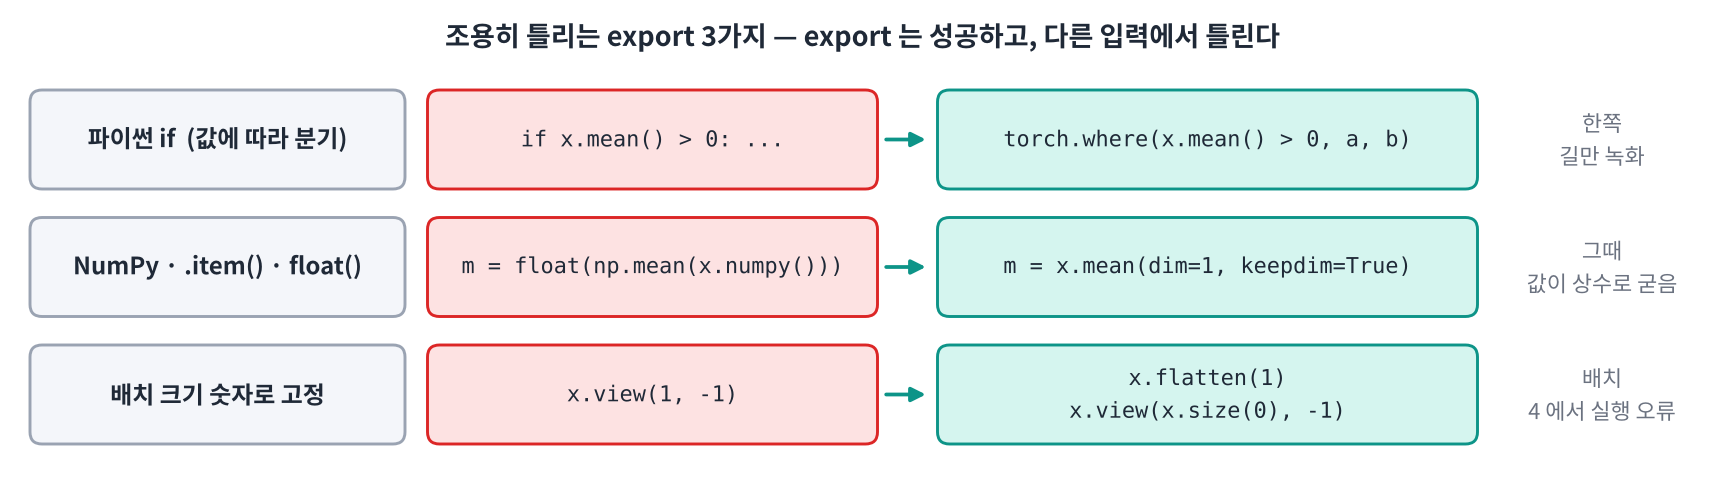

In [ ]:
#@title 🖼 그림 — 조용히 틀리는 export 3가지와 고치는 법
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f6_three.png", embed=True, width=880))

#### ⚠️ 자주 하는 실수

- `verify` 를 **더미 입력 하나**로만 돌림 → 녹화된 길과 같은 입력이라 늘 ✅. 일부러 **다른 경우**(음수 · 어두운 사진 · 배치 4) 를 넣으세요.
- TracerWarning 을 '경고일 뿐' 하고 넘김 → 이 교시의 세 문제가 전부 경고 한 줄로만 알려 줍니다.
- `if self.training:` 같은 **모델 설정**에 따른 분기는 괜찮습니다 — 입력 값과 상관없이 항상 같은 길이니까요. 문제는 **입력 값에 따른** 분기.

#### 📌 6교시 정리

- export = 더미 입력으로 **실행된 길만 녹화**. 파이썬 if · NumPy 값 · 숫자로 쓴 크기는 그 순간의 결과로 굳는다.
- 고치는 법: `torch.where` · torch 연산 (`mean` 등) · `flatten(1)` / `view(x.size(0), -1)`.
- 확인하는 법: **여러 경우의 입력으로 `verify`** + TracerWarning 읽기.

## 7교시 — 미지원 연산 고치기 · onnxslim 단순화

6교시의 문제는 '조용히' 틀렸습니다. 이번엔 반대로 export 가 **오류를 내며 멈추는** 경우입니다. 오류가 나니 오히려 쉽습니다 — 메시지를 읽고 바꾸면 됩니다.

> 🎬 **애니메이션** [D2-7 미지원 연산 · 단순화](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

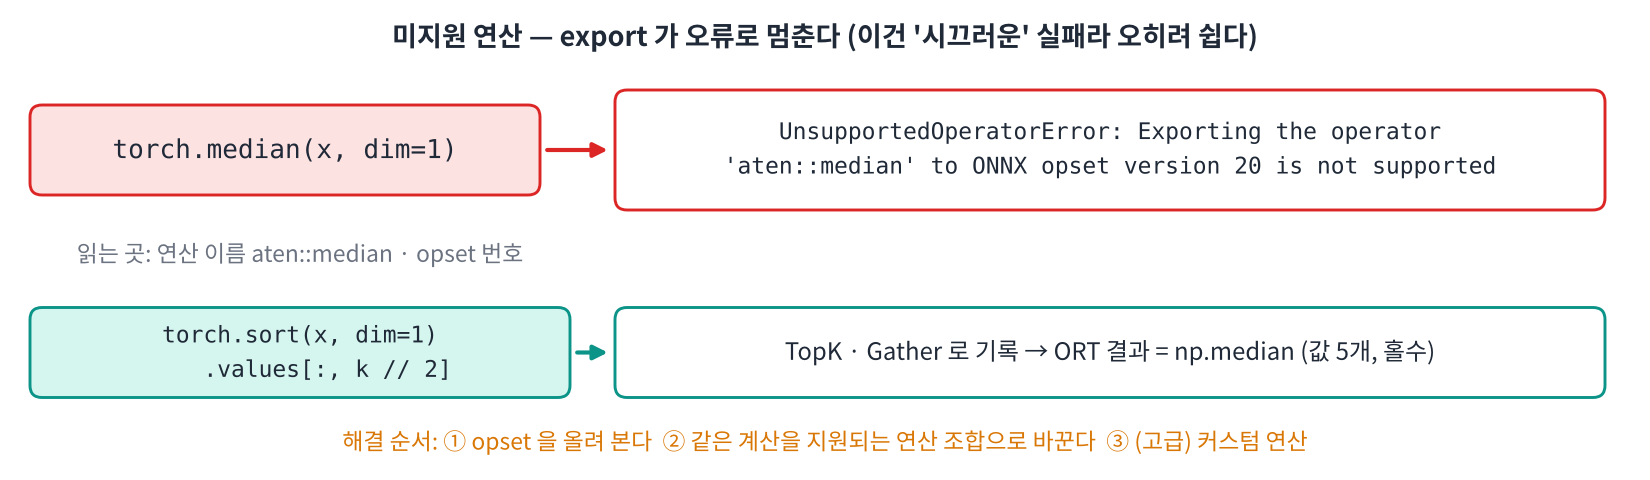

In [ ]:
#@title 🖼 그림 — 미지원 연산 — 오류 읽기와 바꾸기
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f7_unsupported.png", embed=True, width=860))

In [ ]:
class MedianAlarm(nn.Module):
    """센서 5개 값의 중앙값 (튀는 값에 강함) → 경보 2 클래스"""
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(1, 2)

    def forward(self, x):                                   # x: (N, 5)
        med = torch.median(x, dim=1, keepdim=True).values    # (N, 1)
        return self.fc(med)

torch.manual_seed(0)
med_net = MedianAlarm().eval()
try:
    torch.onnx.export(med_net, torch.rand(1, 5), "median.onnx", input_names=["input"], output_names=["logits"], **EXPORT_KW)
except Exception as e:
    err_msg = str(e).split("\n")[0]
    print(type(e).__name__, ":", err_msg)

**문제 7-1** 오류 메시지에서 **ONNX 로 바꾸지 못한 연산의 이름**을 그대로 옮겨 쓰세요 (작은따옴표 안의 이름).

In [ ]:
err_op = "____"

In [ ]:
assert err_op in err_msg and err_op.startswith("aten::"); print("✅", err_op, "— aten = PyTorch 내부 연산 이름")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmVycl9vcCA9ICJhdGVuOjptZWRpYW4iCgrwn5KhIO2VtOyEpArrqZTs"
    "i5zsp4Ag6rWs7KGwOiBFeHBvcnRpbmcgdGhlIG9wZXJhdG9yICfsl7DsgrAg7J2066aEJyB0byBPTk5YIG9wc2V0"
    "IHZlcnNpb24g7YyQIOuyiO2YuCBpcyBub3Qgc3VwcG9ydGVkLgrikaAgb3BzZXRfdmVyc2lvbiDsnYQg7Jis66as"
    "66m0IOuQmOuKlCDqsr3smrDrj4Qg7J6I6rOgICg06rWQ7IucKSwg4pGhIOydtCDqsr3smrDsspjrn7wg7LWc7Iug"
    "IO2MkOyXkOuPhCDsl4bsnLzrqbQg6rCZ7J2AIOqzhOyCsOydhCDsp4Dsm5DrkJjripQg7Jew7IKw7Jy866GcIOuw"
    "lOq/ieuLiOuLpC4="
).decode("utf-8"))

**문제 7-2** 중앙값 = **정렬해서 가운데 값**입니다. `torch.sort` 는 지원됩니다. 값 5개를 정렬한 뒤 가운데(2번) 하나를 모양 유지해 꺼내도록 고치고, **원래 모델(`med_net`, torch.median) 과** 결과가 같은지 확인하세요.

In [ ]:
class MedianAlarmFix(MedianAlarm):
    def forward(self, x):
        k = x.shape[1] // 2
        med = torch.____(x, dim=1).values[:, k:k + 1]        # (N, 1)
        return self.fc(med)

med_fix = MedianAlarmFix().eval()
med_fix.load_state_dict(med_net.state_dict())
export_warn(med_fix, torch.rand(1, 5), "median_fix.onnx", input_names=["input"], output_names=["logits"],
            dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})
cases_m = {"배치 1": np.random.rand(1, 5).astype(np.float32), "배치 6 · 튀는 값": (np.random.rand(6, 5) * [1, 1, 1, 1, 50]).astype(np.float32)}
ok_m = verify(med_net, "median_fix.onnx", cases_m)          # ← 원래 모델과 비교

In [ ]:
assert ok_m; print("✅ torch.median 모델과 같은 결과 — TopK 로 정렬")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmNsYXNzIE1lZGlhbkFsYXJtRml4KE1lZGlhbkFsYXJtKToKICAgIGRl"
    "ZiBmb3J3YXJkKHNlbGYsIHgpOgogICAgICAgIGsgPSB4LnNoYXBlWzFdIC8vIDIKICAgICAgICBtZWQgPSB0b3Jj"
    "aC5zb3J0KHgsIGRpbT0xKS52YWx1ZXNbOiwgazprICsgMV0gICAgICAgICMgKE4sIDEpCiAgICAgICAgcmV0dXJu"
    "IHNlbGYuZmMobWVkKQoKbWVkX2ZpeCA9IE1lZGlhbkFsYXJtRml4KCkuZXZhbCgpCm1lZF9maXgubG9hZF9zdGF0"
    "ZV9kaWN0KG1lZF9uZXQuc3RhdGVfZGljdCgpKQpleHBvcnRfd2FybihtZWRfZml4LCB0b3JjaC5yYW5kKDEsIDUp"
    "LCAibWVkaWFuX2ZpeC5vbm54IiwgaW5wdXRfbmFtZXM9WyJpbnB1dCJdLCBvdXRwdXRfbmFtZXM9WyJsb2dpdHMi"
    "XSwKICAgICAgICAgICAgZHluYW1pY19heGVzPXsiaW5wdXQiOiB7MDogImJhdGNoIn0sICJsb2dpdHMiOiB7MDog"
    "ImJhdGNoIn19KQpjYXNlc19tID0geyLrsLDsuZggMSI6IG5wLnJhbmRvbS5yYW5kKDEsIDUpLmFzdHlwZShucC5m"
    "bG9hdDMyKSwgIuuwsOy5mCA2IMK3IO2KgOuKlCDqsJIiOiAobnAucmFuZG9tLnJhbmQoNiwgNSkgKiBbMSwgMSwg"
    "MSwgMSwgNTBdKS5hc3R5cGUobnAuZmxvYXQzMil9Cm9rX20gPSB2ZXJpZnkobWVkX25ldCwgIm1lZGlhbl9maXgu"
    "b25ueCIsIGNhc2VzX20pICAgICAgICAgICMg4oaQIOybkOuemCDrqqjrjbjqs7wg67mE6rWQCgrwn5KhIO2VtOyE"
    "pAp2ZXJpZnkg7J2YIOyyqyDsnbjsnpDroZwgJ+ybkOuemCDrqqjrjbgnIOydhCDrhKPsnYAg6rKD7J20IO2VteyL"
    "rCDigJQg6rOg7LmcIE9OTlgg6rCAIOybkOuemCDsnZjrj4QodG9yY2gubWVkaWFuKSDsmYAg6rCZ7J2A7KeAIO2Z"
    "leyduO2VqeuLiOuLpC4K6rCS7J20IDXqsJwgKO2ZgOyImCkg6528IOqwgOyatOuNsCDqsJIgPSDspJHslZnqsJIu"
    "IOynneyImOuptCB0b3JjaC5tZWRpYW4g7J2AIOuRkCDqsIDsmrTrjbAg6rCSIOykkSDsnpHsnYAg7Kq97J2EIOyk"
    "jeuLiOuLpC4K64W465Oc6rCAIDIx6rCc64KYIOuQmOuKlCDsnbTsnKA6IGsgPSB4LnNoYXBlWzFdIC8vIDIg66W8"
    "IOunpOuyiCDqs4TsgrDtlZjrj4TroZ0gU2hhcGUgwrcgR2F0aGVyIMK3IERpdiDCtyBTbGljZSDrhbjrk5zqsIAg"
    "6riw66Gd65CY7JeI6riwIOuVjOusuCAoNuq1kOyLnCDikaIg6rO8IOuLrOumrCDsiKvsnpDroZwg6rWz7KeAIOyV"
    "iuydjCkuCuyVhOuemCBvbm54c2xpbSDsnYQg67Cw7Jq0IOuSpCBtZWRpYW5fZml4Lm9ubngg7JeQ64+EIOyggeya"
    "qe2VtCDrhbjrk5wg7IiY6rCAIOyWvOuniOuCmCDspITslrTrk5zripTsp4Ag67O07IS47JqULg=="
).decode("utf-8"))

### onnxslim — 같은 계산, 더 적은 노드

export 된 그래프에는 **계산해 보면 늘 같은 값**인 부분이 남아 있곤 합니다. 대표적인 예가 `x.view(x.size(0), -1)` — 배치 크기를 매번 읽어 shape 를 조립하는 노드들입니다. **onnxslim** 은 이런 부분을 미리 계산해 접고(constant folding), 쓸모없는 노드를 지웁니다.

In [ ]:
class ViewNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 4, 3)
        self.bn = nn.BatchNorm2d(4)
        self.fc = nn.Linear(4 * 26 * 26, 10)

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = x.view(x.size(0), -1)                  # 배치 크기를 읽어서 편다
        return self.fc(x)

torch.manual_seed(0)
view_net = ViewNet().eval()
torch.onnx.export(view_net, torch.zeros(1, 1, 28, 28), "viewnet.onnx", input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, **EXPORT_KW)
display(describe_onnx("viewnet.onnx")[["op_type", "data_in", "out", "params"]])

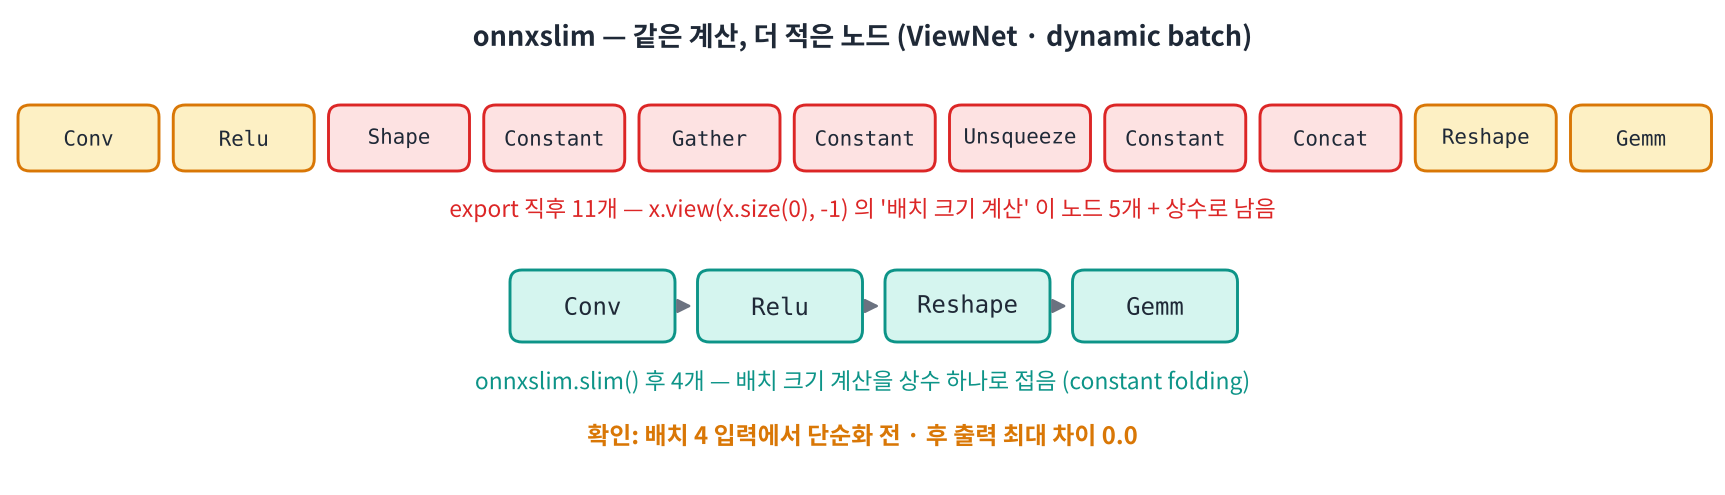

In [ ]:
#@title 🖼 그림 — onnxslim — 11개 노드가 4개로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f7_slim.png", embed=True, width=880))

**문제 7-3** `onnxslim.slim(경로)` 는 단순화된 **모델 객체**를 돌려줍니다. `onnx.save` 로 `viewnet_slim.onnx` 에 저장하고, 노드 수 전 · 후와 **결과가 같은지**(배치 4) 비교하세요.

In [ ]:
slim_model = onnxslim.____("viewnet.onnx")
onnx.save(slim_model, "viewnet_slim.onnx")
before = [n.op_type for n in onnx.load("viewnet.onnx").graph.node]
after = [n.op_type for n in onnx.load("viewnet_slim.onnx").graph.node]
print(f"{len(before)}개 → {len(after)}개 :", after)
x4 = np.random.rand(4, 1, 28, 28).astype(np.float32)
r0 = ort.InferenceSession("viewnet.onnx", providers=["CPUExecutionProvider"]).run(None, {"input": x4})[0]
r1 = ort.InferenceSession("viewnet_slim.onnx", providers=["CPUExecutionProvider"]).run(None, {"input": x4})[0]
print("단순화 전 · 후 최대 차이:", np.abs(r0 - r1).____())

In [ ]:
assert len(after) < len(before) and "Shape" not in after and np.allclose(r0, r1, atol=1e-5)
print("✅ 배치 크기 계산 노드가 사라지고 결과는 그대로")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACnNsaW1fbW9kZWwgPSBvbm54c2xpbS5zbGltKCJ2aWV3bmV0Lm9ubngi"
    "KQpvbm54LnNhdmUoc2xpbV9tb2RlbCwgInZpZXduZXRfc2xpbS5vbm54IikKYmVmb3JlID0gW24ub3BfdHlwZSBm"
    "b3IgbiBpbiBvbm54LmxvYWQoInZpZXduZXQub25ueCIpLmdyYXBoLm5vZGVdCmFmdGVyID0gW24ub3BfdHlwZSBm"
    "b3IgbiBpbiBvbm54LmxvYWQoInZpZXduZXRfc2xpbS5vbm54IikuZ3JhcGgubm9kZV0KcHJpbnQoZiJ7bGVuKGJl"
    "Zm9yZSl96rCcIOKGkiB7bGVuKGFmdGVyKX3qsJwgOiIsIGFmdGVyKQp4NCA9IG5wLnJhbmRvbS5yYW5kKDQsIDEs"
    "IDI4LCAyOCkuYXN0eXBlKG5wLmZsb2F0MzIpCnIwID0gb3J0LkluZmVyZW5jZVNlc3Npb24oInZpZXduZXQub25u"
    "eCIsIHByb3ZpZGVycz1bIkNQVUV4ZWN1dGlvblByb3ZpZGVyIl0pLnJ1bihOb25lLCB7ImlucHV0IjogeDR9KVsw"
    "XQpyMSA9IG9ydC5JbmZlcmVuY2VTZXNzaW9uKCJ2aWV3bmV0X3NsaW0ub25ueCIsIHByb3ZpZGVycz1bIkNQVUV4"
    "ZWN1dGlvblByb3ZpZGVyIl0pLnJ1bihOb25lLCB7ImlucHV0IjogeDR9KVswXQpwcmludCgi64uo7Iic7ZmUIOyg"
    "hCDCtyDtm4Qg7LWc64yAIOywqOydtDoiLCBucC5hYnMocjAgLSByMSkubWF4KCkpCgrwn5KhIO2VtOyEpApTaGFw"
    "ZSDihpIgR2F0aGVyIOKGkiBVbnNxdWVlemUg4oaSIENvbmNhdCDsnYAgJ+uwsOy5mCDtgazquLAsIC0xJyDsnbTr"
    "nbzripQgc2hhcGUg66W8IOunpOuyiCDsobDrpr3tlZjripQg64W465Oc65OkLgpSZXNoYXBlIOuKlCAnMCDsnYAg"
    "6re464yA66GcLCAtMSDsnYAg64KY66i47KeAJyDrnbzripQg6rec7LmZ7J20IOyeiOyWtCDsg4HsiJggc2hhcGUg"
    "7ZWY64KY66GcIOuwlOq/gCDsiJgg7J6I7Iq164uI64ukIOKAlCDqt7jrnpjshJwgZHluYW1pYyDrsLDsuZjripQg"
    "6re464yA66GcIOycoOyngOuQqeuLiOuLpC4K64W465Oc6rCAIOyggeycvOuptCBOZXRyb24g7Jy866GcIOydveq4"
    "sCDsib3qs6AsIERheSA0IFRlbnNvclJUIOuzgO2ZmOuPhCDrjZwg6rmM64uk66Gt7Iq164uI64ukLiDqt7jrnpjr"
    "j4Qg64uo7Iic7ZmUIO2bhOyXkOuKlCDrsJjrk5zsi5wg67mE6rWQIQ=="
).decode("utf-8"))

### 🔁 바꿔보기 — 상수 접기를 끄고 내보내면?

`torch.onnx.export` 도 기본으로 상수를 어느 정도 접습니다 (`do_constant_folding=True`). 이것을 끄면 그래프가 얼마나 커지는지, onnxslim 이 어디까지 줄이는지 보세요.

In [ ]:
torch.onnx.export(view_net, torch.zeros(1, 1, 28, 28), "viewnet_nofold.onnx", input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, do_constant_folding=False, **EXPORT_KW)
nf = [n.op_type for n in onnx.load("viewnet_nofold.onnx").graph.node]
onnx.save(onnxslim.slim("viewnet_nofold.onnx"), "viewnet_nofold_slim.onnx")
nfs = [n.op_type for n in onnx.load("viewnet_nofold_slim.onnx").graph.node]
print(f"접기 끔 {len(nf)}개:", nf)
print(f"onnxslim 후 {len(nfs)}개:", nfs)

#### ⚠️ 자주 하는 실수

- `onnxslim.slim(...)` 결과를 저장하지 않고 원래 파일을 다시 씀 → 결과는 **모델 객체**, `onnx.save` 필요.
- 미지원 연산을 만나 **모델 구조를 크게 바꿈** → 바꾼 뒤에는 반드시 **원래 모델과** verify.
- 단순화 = 정확도가 오르는 것으로 착각 → 같은 계산을 더 짧게 적을 뿐, 결과는 같아야 합니다.

#### 📌 7교시 정리

- 미지원 연산: 메시지에서 `'aten::연산'` · opset 확인 → opset 올리기 또는 지원 연산 조합으로 바꾸기 → **원래 모델과 verify**.
- `onnxslim.slim(path)` → `onnx.save` — 상수 접기 · 불필요 노드 제거. ViewNet 11개 → 4개.
- 단순화 전후도 allclose.

## 8교시 — 미니 프로젝트: 고장 난 BrightNet 고쳐 배포하기

현장 카메라용 분류기 **BrightNet** 은 PyTorch 에서는 잘 돌지만, ONNX 로 내보내면 이상하게 동작합니다. 오늘 배운 것을 모두 써서 고치고, **배포용 최종 파일** `brightnet_final.onnx` 를 만듭니다. (가중치는 seed 로 고정한 연습용 값입니다. 정확도가 아니라 **배포 과정**이 과제입니다.)

**BrightNet 의 의도** — 사진 **한 장마다**: ① 어두우면(평균 < 0.3) 2배 밝게 → ② 평균을 빼서 밝기 보정 → ③ CNN → 3 클래스 (`safe` · `warning` · `danger`). 입력은 64×64 컬러, 0~1.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 고장 찾기 — 그대로 내보내 `verify` 하고 실패한 경우 고르기 | 10 |
| 2 | `BrightNetFixed` — 고장 3곳 고치기 | 30 |
| 3 | 배포용 export — 배치 자유 · opset 17 · 이름 `input` / `logits` | 20 |
| 4 | 점검 · 단순화 — checker · shape_inference · onnxslim → `brightnet_final.onnx` | 20 |
| 5 | 최종 확인 — 배치 1 · 8, 어두운 · 밝은 사진 | 10 |
| 6 | 결과 해석 (마크다운 답변) | 10 |

과제 끝의 **채점 셀**을 실행하면 자동 채점 점수가 나옵니다 (과제 6 은 강사 채점).

> 🎬 **애니메이션** [D2-8 BrightNet 고치기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/animation.html#d2-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day2/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

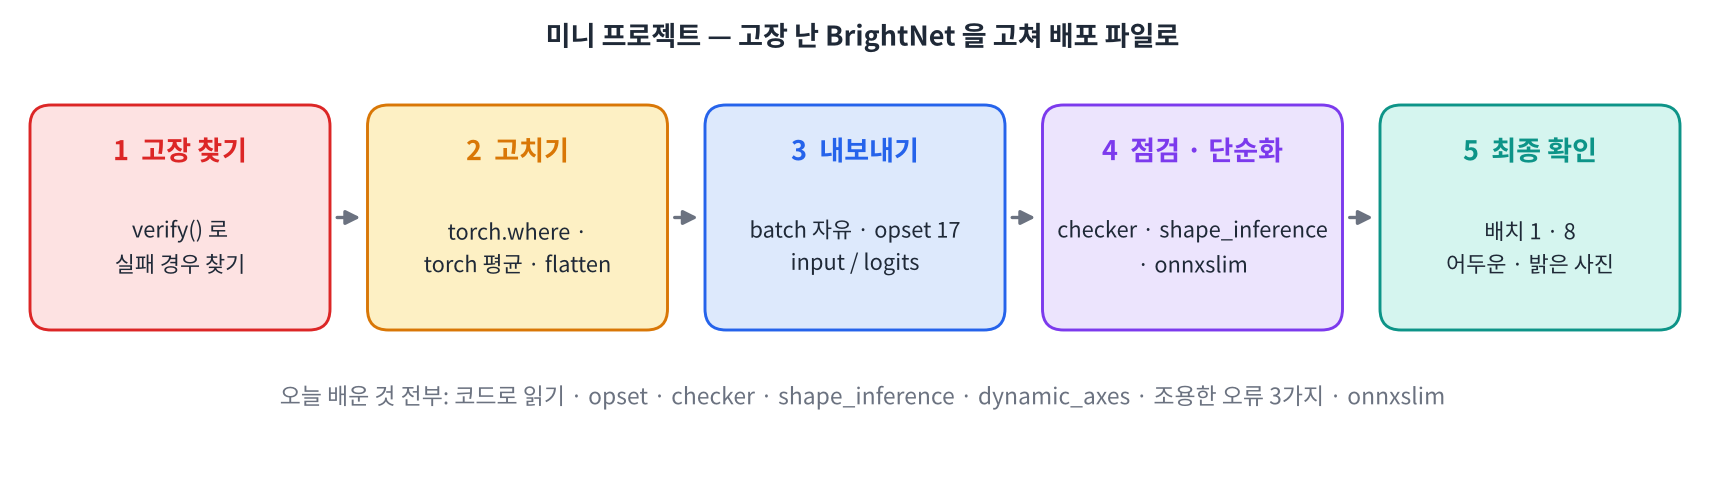

In [ ]:
#@title 🖼 그림 — 미니 프로젝트 흐름
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day2/img/f8_project.png", embed=True, width=880))

In [ ]:
class BrightNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),      # → (8, 32, 32)
            nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(4))    # → (16, 8, 8)
        self.fc = nn.Linear(16 * 8 * 8, 3)

    def forward(self, x):
        if x.mean() < 0.3:                          # ① 어두우면 2배 밝게
            x = x * 2
        m = float(np.mean(x.detach().numpy()))      # ② 평균을 빼서 밝기 보정
        x = x - m
        x = self.features(x)
        x = x.view(1, -1)                           # ③ 펴기
        return self.fc(x)

def make_bright():
    torch.manual_seed(11)
    net = BrightNet()
    with torch.no_grad():
        for b in net.modules():
            if isinstance(b, nn.BatchNorm2d):
                b.running_mean.uniform_(-0.1, 0.1); b.running_var.uniform_(0.5, 1.5)
    return net.eval()

BRIGHT = ["safe", "warning", "danger"]
bright = make_bright()

def load64(name, scale=1.0):
    img = cv2.cvtColor(cv2.imread(fetch(name)), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32) / 255 * scale
    return np.ascontiguousarray(img.transpose(2, 0, 1)[None])              # (1, 3, 64, 64)

photos = {n: load64(n) for n in ["butterfly.jpg", "orange.jpg", "baboon.jpg"]}
dark = {n.replace(".jpg", "_dark"): load64(n, 0.25) for n in ["butterfly.jpg", "orange.jpg", "baboon.jpg"]}
for k, v in {**photos, **dark}.items():
    print(k.ljust(14), v.shape, f"평균 밝기 {v.mean():.3f}", "→ 어두움" if v.mean() < 0.3 else "")

def intended(x):
    """BrightNet 의 '의도' — 사진을 한 장씩 넣은 PyTorch 결과를 쌓는다 (채점 기준)"""
    with torch.no_grad():
        return np.concatenate([bright(torch.from_numpy(x[i:i + 1])).numpy() for i in range(len(x))])

### 과제 1 — 고장 찾기 (10점)

BrightNet 을 **그대로** 내보내고 (더미 = `orange.jpg`), 세 가지 경우로 `verify` 합니다. 실행 결과를 보고 **❌ 가 나온 경우의 이름**을 `failed` 리스트에 쓰세요.

In [ ]:
dummy_b = torch.from_numpy(photos["orange.jpg"])
export_warn(bright, dummy_b, "brightnet_broken.onnx", input_names=["input"], output_names=["logits"],
            dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})
cases_b = {"더미 그대로": photos["orange.jpg"], "다른 밝은 사진": photos["butterfly.jpg"], "어두운 사진": dark["butterfly_dark"]}
verify(bright, "brightnet_broken.onnx", cases_b)

In [ ]:
failed = [____]                 # 예: ["더미 그대로"] — 위 결과에서 ❌ 인 이름을 그대로

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACmZhaWxlZCA9IFsi64uk66W4IOuwneydgCDsgqzsp4QiLCAi7Ja065GQ"
    "7Jq0IOyCrOynhCJdCgrwn5KhIO2VtOyEpArrjZTrr7gob3JhbmdlKSDsmYAg6rCZ7J2AIOyeheugpeunjCDinIUu"
    "IOKRoSDtj4nqt6AgbSDsnbQgb3JhbmdlIOydmCDtj4nqt6DsnLzroZwg6rWz7Ja0IOuLpOuluCDsgqzsp4TsnYAg"
    "66qo65GQIO2LgOumrOqzoCwK7Ja065GQ7Jq0IOyCrOynhOydgCDikaAgaWYg64+EIOuFue2ZlOuQmOyngCDslYrs"
    "lYQgKG9yYW5nZSDripQg67Cd7Jy866+A66GcICfrsJ3qsowg7ZWY7KeAIOyViuuKlCDquLgnIOunjCDrhbntmZQp"
    "IOuNlCDtgazqsowg7YuA66a964uI64ukLgrrsLDsuZggMiDsnbTsg4HsnYAg4pGiIHZpZXcoMSwgLTEpIOuVjOus"
    "uOyXkCDsi6Ttlokg7Jik66WY6rCAIOuCqeuLiOuLpCAo6rO87KCcIDUg7JeQ7IScIO2ZleyduCku"
).decode("utf-8"))

### 과제 2 — 고장 3곳 고치기 (30점)

`BrightNet` 을 상속해 `forward` 만 다시 씁니다. 6교시의 세 가지 고치는 법을 그대로 쓰되, **사진마다** 따로 계산되도록 평균은 `dim=(1, 2, 3), keepdim=True` (채널 · 높이 · 너비) 로 구합니다.

In [ ]:
class BrightNetFixed(BrightNet):
    def forward(self, x):
        mean = x.mean(dim=(1, 2, 3), keepdim=True)              # (N, 1, 1, 1) — 사진마다 평균
        x = torch.____(mean < 0.3, x * 2, x)                     # ① if → 두 길을 모두
        x = x - x.____(dim=(1, 2, 3), keepdim=True)              # ② NumPy → torch 연산
        x = self.features(x)
        x = x.____(1)                                            # ③ 배치 축은 그대로
        return self.fc(x)

fixed = BrightNetFixed().eval()
fixed.load_state_dict(bright.state_dict())                      # 같은 가중치
X_all = np.ascontiguousarray(np.concatenate([*photos.values(), *dark.values()]))   # (6, 3, 64, 64)
with torch.no_grad():
    out_fixed = fixed(torch.from_numpy(X_all)).numpy()
print("고친 모델 (배치 6) vs 의도 (한 장씩) 최대 차이:", np.abs(out_fixed - intended(X_all)).max())

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACmNsYXNzIEJyaWdodE5ldEZpeGVkKEJyaWdodE5ldCk6CiAgICBkZWYg"
    "Zm9yd2FyZChzZWxmLCB4KToKICAgICAgICBtZWFuID0geC5tZWFuKGRpbT0oMSwgMiwgMyksIGtlZXBkaW09VHJ1"
    "ZSkgICAgICAgICAgICAgICMgKE4sIDEsIDEsIDEpIOKAlCDsgqzsp4Trp4jri6Qg7Y+J6regCiAgICAgICAgeCA9"
    "IHRvcmNoLndoZXJlKG1lYW4gPCAwLjMsIHggKiAyLCB4KSAgICAgICAgICAgICAgICAgICAgIyDikaAgaWYg4oaS"
    "IOuRkCDquLjsnYQg66qo65GQCiAgICAgICAgeCA9IHggLSB4Lm1lYW4oZGltPSgxLCAyLCAzKSwga2VlcGRpbT1U"
    "cnVlKSAgICAgICAgICAgICAgIyDikaEgTnVtUHkg4oaSIHRvcmNoIOyXsOyCsAogICAgICAgIHggPSBzZWxmLmZl"
    "YXR1cmVzKHgpCiAgICAgICAgeCA9IHguZmxhdHRlbigxKSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgIyDikaIg67Cw7LmYIOy2leydgCDqt7jrjIDroZwKICAgICAgICByZXR1cm4gc2VsZi5mYyh4KQoK"
    "Zml4ZWQgPSBCcmlnaHROZXRGaXhlZCgpLmV2YWwoKQpmaXhlZC5sb2FkX3N0YXRlX2RpY3QoYnJpZ2h0LnN0YXRl"
    "X2RpY3QoKSkgICAgICAgICAgICAgICAgICAgICAgIyDqsJnsnYAg6rCA7KSR7LmYClhfYWxsID0gbnAuYXNjb250"
    "aWd1b3VzYXJyYXkobnAuY29uY2F0ZW5hdGUoWypwaG90b3MudmFsdWVzKCksICpkYXJrLnZhbHVlcygpXSkpICAg"
    "IyAoNiwgMywgNjQsIDY0KQp3aXRoIHRvcmNoLm5vX2dyYWQoKToKICAgIG91dF9maXhlZCA9IGZpeGVkKHRvcmNo"
    "LmZyb21fbnVtcHkoWF9hbGwpKS5udW1weSgpCnByaW50KCLqs6DsuZwg66qo6424ICjrsLDsuZggNikgdnMg7J2Y"
    "64+EICjtlZwg7J6l7JSpKSDstZzrjIAg7LCo7J20OiIsIG5wLmFicyhvdXRfZml4ZWQgLSBpbnRlbmRlZChYX2Fs"
    "bCkpLm1heCgpKQoK8J+SoSDtlbTshKQK7JuQ656YIOy9lOuTnOydmCB4Lm1lYW4oKSDsnYAgJ+uwsOy5mCDsoITs"
    "srQnIO2Pieq3oOydtOudvCwg67Cw7LmY66GcIOuEo+ycvOuptCDrsJ3snYAg7IKs7KeE6rO8IOyWtOuRkOyatCDs"
    "gqzsp4TsnbQg7ISc66Gc7J2YIO2Pieq3oOyXkCDsmIHtlqXsnYQg7KSN64uI64ukLgpkaW09KDEsIDIsIDMpIOyc"
    "vOuhnCDsgqzsp4Trp4jri6Qg6rOE7IKw7ZW07JW8ICftlZwg7J6l7JSpIOuEo+ydgCDqsrDqs7wgKOydmOuPhCkn"
    "IOyZgCDqsJnslYTsp5Hri4jri6Qg4oCUIOydtOqyg+ydtCAn7J2Y64+EJyDrpbwg6riw7KSA7Jy866GcIOu5hOq1"
    "kO2VmOuKlCDsnbTsnKDsnoXri4jri6Qu"
).decode("utf-8"))

### 과제 3 — 배포용 export (20점)

`fixed` 를 `brightnet_fixed.onnx` 로 내보내세요. 조건: 배치 축 자유 (`"batch"`), **opset 17** (배포할 장치가 17 까지 안다고 가정), 이름 `input` / `logits`. `export_warn` 을 써서 TracerWarning 이 없는지도 봅니다.

In [ ]:
export_warn(fixed, dummy_b, "brightnet_fixed.onnx", input_names=["input"], output_names=[____],
            dynamic_axes={"input": {0: ____}, "logits": {0: "batch"}}, opset_version=____)
print(onnx_report("brightnet_fixed.onnx"))

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmV4cG9ydF93YXJuKGZpeGVkLCBkdW1teV9iLCAiYnJpZ2h0bmV0X2Zp"
    "eGVkLm9ubngiLCBpbnB1dF9uYW1lcz1bImlucHV0Il0sIG91dHB1dF9uYW1lcz1bImxvZ2l0cyJdLAogICAgICAg"
    "ICAgICBkeW5hbWljX2F4ZXM9eyJpbnB1dCI6IHswOiAiYmF0Y2gifSwgImxvZ2l0cyI6IHswOiAiYmF0Y2gifX0s"
    "IG9wc2V0X3ZlcnNpb249MTcpCnByaW50KG9ubnhfcmVwb3J0KCJicmlnaHRuZXRfZml4ZWQub25ueCIpKQ=="
).decode("utf-8"))

### 과제 4 — 점검 · 단순화 (20점)

① checker 로 검사 → ② onnxslim 으로 단순화 → ③ shape_inference 로 중간 shape 를 채워 `brightnet_final.onnx` 로 저장 → ④ 다시 checker. 마지막에 `describe_onnx` 로 최종 파일을 표로 봅니다.

In [ ]:
onnx.checker.check_model(onnx.load("brightnet_fixed.onnx"))                     # ①
slim_b = onnxslim.slim("brightnet_fixed.onnx")                                  # ②
final = onnx.shape_inference.____(slim_b)                                       # ③
onnx.save(final, "brightnet_final.onnx")
onnx.checker.____(onnx.load("brightnet_final.onnx"))                            # ④
n_before = len(onnx.load("brightnet_fixed.onnx").graph.node)
n_after = len(onnx.load("brightnet_final.onnx").graph.node)
print(f"노드 {n_before} → {n_after} | 중간 shape {len(final.graph.value_info)}개 | opset {final.opset_import[0].version}")
display(describe_onnx("brightnet_final.onnx")[["op_type", "params"]].T)

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACm9ubnguY2hlY2tlci5jaGVja19tb2RlbChvbm54LmxvYWQoImJyaWdo"
    "dG5ldF9maXhlZC5vbm54IikpICAgICAgICAgICAgICAgICAgICAgIyDikaAKc2xpbV9iID0gb25ueHNsaW0uc2xp"
    "bSgiYnJpZ2h0bmV0X2ZpeGVkLm9ubngiKSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAjIOKRoQpm"
    "aW5hbCA9IG9ubnguc2hhcGVfaW5mZXJlbmNlLmluZmVyX3NoYXBlcyhzbGltX2IpICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICMg4pGiCm9ubnguc2F2ZShmaW5hbCwgImJyaWdodG5ldF9maW5hbC5vbm54IikKb25ueC5j"
    "aGVja2VyLmNoZWNrX21vZGVsKG9ubngubG9hZCgiYnJpZ2h0bmV0X2ZpbmFsLm9ubngiKSkgICAgICAgICAgICAg"
    "ICAgICAgICAjIOKRowpuX2JlZm9yZSA9IGxlbihvbm54LmxvYWQoImJyaWdodG5ldF9maXhlZC5vbm54IikuZ3Jh"
    "cGgubm9kZSkKbl9hZnRlciA9IGxlbihvbm54LmxvYWQoImJyaWdodG5ldF9maW5hbC5vbm54IikuZ3JhcGgubm9k"
    "ZSkKcHJpbnQoZiLrhbjrk5wge25fYmVmb3JlfSDihpIge25fYWZ0ZXJ9IHwg7KSR6rCEIHNoYXBlIHtsZW4oZmlu"
    "YWwuZ3JhcGgudmFsdWVfaW5mbyl96rCcIHwgb3BzZXQge2ZpbmFsLm9wc2V0X2ltcG9ydFswXS52ZXJzaW9ufSIp"
    "CmRpc3BsYXkoZGVzY3JpYmVfb25ueCgiYnJpZ2h0bmV0X2ZpbmFsLm9ubngiKVtbIm9wX3R5cGUiLCAicGFyYW1z"
    "Il1dLlQp"
).decode("utf-8"))

### 과제 5 — 최종 확인 (10점)

최종 파일을 `intended` (한 장씩 넣은 PyTorch) 와 비교합니다. `verify` 는 모델의 결과와 비교하므로, 여기서는 직접 씁니다. 배치 1 (사진 6장 각각) 과 **배치 8** (6장 + 앞 2장 반복) 모두 같아야 합니다.

In [ ]:
sess_final = ort.InferenceSession("brightnet_final.onnx", providers=["CPUExecutionProvider"])
X8 = np.concatenate([X_all, X_all[:2]])                                          # (8, 3, 64, 64)
diff_1 = max(float(np.abs(sess_final.run(None, {"input": X_all[i:i + 1]})[0] - intended(X_all[i:i + 1])).max()) for i in range(6))
out8 = sess_final.run(None, {"input": ____})[0]
diff_8 = float(np.abs(out8 - intended(X8)).____())
final_preds = [BRIGHT[i] for i in out8[:6].argmax(1)]
print(f"배치 1 최대 차이 {diff_1:.1e} | 배치 8 최대 차이 {diff_8:.1e}")
print(dict(zip(list(photos) + list(dark), final_preds)))

In [ ]:
#@title 🔒 정답 보기 8-5 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTUg4pSA4pSACnNlc3NfZmluYWwgPSBvcnQuSW5mZXJlbmNlU2Vzc2lvbigiYnJpZ2h0"
    "bmV0X2ZpbmFsLm9ubngiLCBwcm92aWRlcnM9WyJDUFVFeGVjdXRpb25Qcm92aWRlciJdKQpYOCA9IG5wLmNvbmNh"
    "dGVuYXRlKFtYX2FsbCwgWF9hbGxbOjJdXSkgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAjICg4LCAzLCA2NCwgNjQpCmRpZmZfMSA9IG1heChmbG9hdChucC5hYnMoc2Vzc19maW5hbC5ydW4oTm9uZSwg"
    "eyJpbnB1dCI6IFhfYWxsW2k6aSArIDFdfSlbMF0gLSBpbnRlbmRlZChYX2FsbFtpOmkgKyAxXSkpLm1heCgpKSBm"
    "b3IgaSBpbiByYW5nZSg2KSkKb3V0OCA9IHNlc3NfZmluYWwucnVuKE5vbmUsIHsiaW5wdXQiOiBYOH0pWzBdCmRp"
    "ZmZfOCA9IGZsb2F0KG5wLmFicyhvdXQ4IC0gaW50ZW5kZWQoWDgpKS5tYXgoKSkKZmluYWxfcHJlZHMgPSBbQlJJ"
    "R0hUW2ldIGZvciBpIGluIG91dDhbOjZdLmFyZ21heCgxKV0KcHJpbnQoZiLrsLDsuZggMSDstZzrjIAg7LCo7J20"
    "IHtkaWZmXzE6LjFlfSB8IOuwsOy5mCA4IOy1nOuMgCDssKjsnbQge2RpZmZfODouMWV9IikKcHJpbnQoZGljdCh6"
    "aXAobGlzdChwaG90b3MpICsgbGlzdChkYXJrKSwgZmluYWxfcHJlZHMpKSk="
).decode("utf-8"))

### 과제 6 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. 과제 1 에서 '더미 그대로' 만 ✅ 였던 이유를 BrightNet 코드의 ① · ② 와 연결해 설명하세요.
2. 과제 2 에서 평균을 `x.mean()` 이 아니라 `x.mean(dim=(1, 2, 3), keepdim=True)` 로 구해야 하는 이유는? (배치 8 에 밝은 사진과 어두운 사진이 섞여 있을 때를 생각해 보세요.)
3. 과제 4 에서 checker · shape_inference · onnxslim 이 각각 무엇을 해 주었고, **해 주지 않는 것**은 무엇인가요?
4. 배포 담당자에게 `brightnet_final.onnx` 를 넘길 때 함께 적어 줄 정보를 3가지 쓰세요. (힌트: opset · 입력 shape · 전처리)

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4gZXhwb3J0IOuKlCDrjZTrr7gob3JhbmdlLCDrsJ3snYwpIOuhnCDsi6Tt"
    "lonrkJwg6ri466eMIOuFue2ZlO2VqeuLiOuLpC4g4pGgIGlmIOuKlCAn67Cd6rKMIO2VmOyngCDslYrripQg6ri4"
    "JyDrp4wg64Ko7JWEIOyWtOuRkOyatCDsgqzsp4Trj4Qg67Cd7Z6I7KeAIOyViuqzoCwKICAg4pGhIE51bVB5IO2P"
    "ieq3oCBtIOydgCBvcmFuZ2Ug7J2YIO2Pieq3oCDsiKvsnpDroZwg6rWz7Ja0IOuLpOuluCDsgqzsp4Tsl5Drj4Qg"
    "6re4IOyIq+yekOulvCDruo3ri4jri6QuIOq3uOuemOyEnCDrjZTrr7jsmYAg6rCZ7J2AIOyeheugpeunjCDrp57q"
    "s6Ag64KY66i47KeA64qUIO2LgOumveuLiOuLpC4KMi4geC5tZWFuKCkg7J2AIOuwsOy5mCDsoITssrQg7Y+J6reg"
    "IO2VmOuCmOudvCAn7Ja065GQ7Jq06rCAPycg7YyQ7KCV6rO8IO2Pieq3oCDrubzquLDqsIAg64uk66W4IOyCrOyn"
    "hOyXkCDsmIHtlqXsnYQg67Cb7Iq164uI64ukLiDrsJ3snYAg7IKs7KeE7J20IOyEnuydtOuptCDslrTrkZDsmrQg"
    "7IKs7KeE7J2EIOuwne2eiOyngCDslYrsnYQg7IiY64+EIOyeiOyKteuLiOuLpC4KICAgZGltPSgxLCAyLCAzKSwg"
    "a2VlcGRpbT1UcnVlIOuKlCDsgqzsp4Trp4jri6QgKE4sIDEsIDEsIDEpIO2Pieq3oOydhCDqtaztlbQg7ZWcIOye"
    "peyUqSDrhKPsnYAg6rKw6rO8ICjsnZjrj4QpIOyZgCDqsJnqsowg66eM65Ot64uI64ukLgozLiBjaGVja2VyOiDt"
    "mJXsi50gwrcg6rec7LmZICjrgYrquLQg7ZmU7IK07ZGcLCDsiJzshJwpIOqygOyCrC4gc2hhcGVfaW5mZXJlbmNl"
    "OiDspJHqsIQg7ZmU7IK07ZGcIHNoYXBlIOulvCDssYTsm4AuIG9ubnhzbGltOiDsg4HsiJgg7KCR6riwIMK3IOu2"
    "iO2VhOyalCDrhbjrk5wg7KCc6rGw66GcIOuFuOuTnCDsiJgg6rCQ7IaMLgogICDshLgg64+E6rWsIOuqqOuRkCAn"
    "6rKw6rO86rCAIOydmOuPhOyZgCDqsJnsnYDsp4AnIOuKlCDtmZXsnbjtlbQg7KO87KeAIOyViuyKteuLiOuLpCDi"
    "hpIg6rO87KCcIDUg7J2YIOu5hOq1kCAoYWxsY2xvc2UpIOqwgCDrlLDroZwg7ZWE7JqU7ZWp64uI64ukLgo0LiBv"
    "cHNldCAxNyAvIOyeheugpSDsnbTrpoQgaW5wdXQgwrcgc2hhcGUgW2JhdGNoLCAzLCA2NCwgNjRdIMK3IGZsb2F0"
    "MzIgLyDsoITsspjrpqwgKFJHQiwgNjTDlzY0IHJlc2l6ZSwgMH4xID0gLzI1NSwg7KCV6rec7ZmUIOyXhuydjCDi"
    "gJQg67Cd6riwIOuztOygleydgCDrqqjrjbgg7JWI7JeQIOyeiOydjCkgLwogICDstpzroKUgbG9naXRzIFtiYXRj"
    "aCwgM10g6rO8IO2BtOuemOyKpCDsiJzshJwgKHNhZmUgwrcgd2FybmluZyDCtyBkYW5nZXIpLg=="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    assert sorted(failed) == ["다른 밝은 사진", "어두운 사진"]
    score += 10; print("✅ 과제 1  +10")
except Exception as e: print("❌ 과제 1", e)
try:
    xs = torch.from_numpy(np.concatenate([X_all, X_all[::-1]]))
    with torch.no_grad():
        got = fixed(xs).numpy()
    assert np.allclose(got, intended(xs.numpy()), atol=1e-4)
    assert type(fixed).forward is not BrightNet.forward
    score += 30; print("✅ 과제 2  +30")
except Exception as e: print("❌ 과제 2", e)
try:
    m3 = onnx.load("brightnet_fixed.onnx"); s3 = ort.InferenceSession("brightnet_fixed.onnx", providers=["CPUExecutionProvider"])
    assert m3.opset_import[0].version == 17 and s3.get_inputs()[0].name == "input" and s3.get_outputs()[0].name == "logits"
    assert s3.get_inputs()[0].shape == ["batch", 3, 64, 64]
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", e)
try:
    m4 = onnx.load("brightnet_final.onnx"); onnx.checker.check_model(m4)
    assert len(m4.graph.value_info) > 0 and len(m4.graph.node) <= len(onnx.load("brightnet_fixed.onnx").graph.node)
    assert m4.opset_import[0].version == 17
    score += 20; print("✅ 과제 4  +20", f"(노드 {len(m4.graph.node)}개 · 중간 shape {len(m4.graph.value_info)}개)")
except Exception as e: print("❌ 과제 4", e)
try:
    s5 = ort.InferenceSession("brightnet_final.onnx", providers=["CPUExecutionProvider"])
    Xr = np.concatenate([X_all[::-1], X_all[:2]])
    assert np.allclose(s5.run(None, {"input": Xr})[0], intended(Xr), atol=1e-4) and diff_1 < 1e-4 and diff_8 < 1e-4
    assert len(final_preds) == 6 and all(p in BRIGHT for p in final_preds)
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", e)
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점)")

#### 📌 8교시 정리

- 고장 찾기는 **여러 경우의 입력** (더미 · 다른 사진 · 어두운 사진 · 배치) 으로. 더미 하나로는 늘 ✅.
- 기준은 '원래 코드' 가 아니라 **의도** — 한 장씩 넣은 결과와 같아야 한다.
- 배포 파일 만들기 = 고치기 → export (batch · opset · 이름) → checker → onnxslim → shape_inference → **최종 비교**.

## 오늘의 정리

### 셀프 체크

- [ ] `onnx.load` → `graph` 의 input · node · initializer · output 을 코드로 꺼낼 수 있다
- [ ] 노드의 input · output **이름**으로 화살표를 따라갈 수 있다
- [ ] 가중치 (`numpy_helper.to_array`) · 속성 (`helper.get_attribute_value`) 을 꺼내 `describe_onnx` 표를 만들 수 있다
- [ ] opset 이 무엇인지, 왜 `opset_version` 을 정하는지 말할 수 있다 (GELU 예)
- [ ] checker 와 shape_inference 가 하는 일 · 하지 않는 일을 구분할 수 있다
- [ ] `dynamic_axes` 로 배치 축을 열고, dynamic 이 '약속일 뿐' 인 이유 (Flatten → Gemm) 를 설명할 수 있다
- [ ] 조용히 틀리는 export 3가지 (if · NumPy · 숫자 고정) 를 찾고 고칠 수 있다
- [ ] 미지원 연산 오류를 읽고 지원 연산으로 바꾼 뒤 원래 모델과 비교할 수 있다
- [ ] onnxslim 으로 단순화하고 전후 결과를 비교할 수 있다

### 내일 (Day 3) 예고

오늘 5교시에 '느낌만' 본 속도를 **제대로** 잽니다. warm-up · 평균 · p95 · FPS 를 계산하는 `bench()` 함수를 만들고, 스레드 수 · 그래프 최적화 레벨 · **CPU → GPU** 를 한 번에 하나씩 바꿔 가며 성능표에 행을 쌓습니다. 오늘 만든 **`describe_onnx` · `verify` · `mnist_cnn_dyn.onnx`** 를 그대로 씁니다 — Drive 에 노트북 사본을 꼭 저장해 두세요.